<a href="https://colab.research.google.com/github/Fugant1/AGORA/blob/main/ser_sft.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cloud Connection
Drive

In [1]:
from pathlib import Path

In [2]:
def mount_drive():
    """Mount Google Drive in Colab."""
    from google.colab import drive
    drive.mount("/content/drive")

In [3]:
mount_drive()

Mounted at /content/drive


# Get Audio Data
MELD

## Raw

In [4]:
from pathlib import Path
import os
import subprocess
import time
import pandas as pd

In [5]:

DRIVE_ARCHIVE = Path("/content/drive/MyDrive/SER_DPO/MELD/MELD.tar")
MELD_DIR = Path("/content/MELD")
TRAIN_DIR = MELD_DIR / "preprocessed_train_splits"

In [6]:
def extract_tar(archive_path: Path, destination: Path):
    """Extract a .tar archive to destination."""
    archive_path = Path(archive_path)
    destination = Path(destination)

    if not archive_path.exists():
        raise FileNotFoundError(f"Archive not found: {archive_path}")

    destination.mkdir(parents=True, exist_ok=True)

    print(f"Extracting {archive_path.name} → {destination}")
    start = time.time()

    subprocess.run(
        ["tar", "-xf", str(archive_path), "-C", str(destination)],
        check=True,
    )

    elapsed = time.time() - start
    print(f"Extraction completed in {elapsed:.1f}s")

In [7]:

def dataset_info(path: Path):
    """Print basic information about an extracted dataset."""
    path = Path(path)

    n_files = sum(1 for p in path.rglob("*") if p.is_file())

    size = subprocess.run(
        ["du", "-sh", str(path)],
        capture_output=True,
        text=True,
        check=True,
    ).stdout.split()[0]

    print(f"Files: {n_files:,}")
    print(f"Size:  {size}")

In [8]:
def find_file(root: Path, pattern: str) -> Path:
    """Find the first file matching a pattern."""
    matches = list(Path(root).rglob(pattern))

    if not matches:
        raise FileNotFoundError(
            f"Could not find '{pattern}' under {root}"
        )

    return matches[0]


In [9]:
def load_meld_split(split_dir: Path, split: str = "train") -> pd.DataFrame:
    """
    Load a MELD split and resolve audio paths.

    Expected files:
        {split}_preprocessed.csv
        {split}_sent_emo.csv
        *.wav
    """
    split_dir = Path(split_dir)

    audio_files = list(split_dir.rglob("*.wav"))

    preprocessed_csv = find_file(
        split_dir,
        f"{split}_preprocessed.csv",
    )

    emotion_csv = find_file(
        split_dir,
        f"{split}_sent_emo.csv",
    )

    df = pd.read_csv(preprocessed_csv)
    df_emo = pd.read_csv(emotion_csv)

    # Resolve audio filenames → absolute paths
    audio_map = {
        path.name: str(path.resolve())
        for path in audio_files
    }

    df["audio_path"] = (
        df["audio_path"]
        .astype(str)
        .map(lambda x: Path(x).name)
        .map(audio_map)
    )

    # Normalize merge keys
    df["dialogue"] = df["dialogue"].astype(int)
    df["utterance"] = df["utterance"].astype(int)

    df_emo["Dialogue_ID"] = df_emo["Dialogue_ID"].astype(int)
    df_emo["Utterance_ID"] = df_emo["Utterance_ID"].astype(int)

    # Add MELD metadata
    df = df.merge(
        df_emo[
            [
                "Dialogue_ID",
                "Utterance_ID",
                "Emotion",
                "Utterance",
                "Speaker",
            ]
        ],
        left_on=["dialogue", "utterance"],
        right_on=["Dialogue_ID", "Utterance_ID"],
        how="left",
    )

    df = (
        df.drop(columns=["Dialogue_ID", "Utterance_ID"])
          .rename(
              columns={
                  "Utterance": "text",
                  "Emotion": "emotion",
                  "Speaker": "speaker",
              }
          )
    )

    # Validation
    missing_audio = df["audio_path"].isna().sum()
    missing_emotion = df["emotion"].isna().sum()

    print(f"Loaded {len(df):,} samples")
    print(
        f"Audio matched: "
        f"{len(df) - missing_audio:,}/{len(df):,}"
    )

    if missing_audio:
        print(f"Warning: {missing_audio:,} audio files missing")

    print(
        f"Metadata matched: "
        f"{len(df) - missing_emotion:,}/{len(df):,}"
    )

    if missing_emotion:
        print(f"Warning: {missing_emotion:,} metadata rows missing")

    return df

In [10]:
def load_meld(
    archive_path: Path = DRIVE_ARCHIVE,
    destination: Path = MELD_DIR,
    split: str = "train",
) -> pd.DataFrame:
    """Download/extract and load a MELD split."""

    if not destination.exists():
        extract_tar(archive_path, destination)
    else:
        print(f"Dataset already exists: {destination}")

    dataset_info(destination)

    split_dir = destination / f"preprocessed_{split}_splits"

    if not split_dir.exists():
        raise FileNotFoundError(
            f"Split directory not found: {split_dir}"
        )

    return load_meld_split(split_dir, split)

In [11]:
raw_train_set = load_meld(
      archive_path=DRIVE_ARCHIVE,
      destination=MELD_DIR,
      split="train",
  )
raw_train_set = pd.read_csv("/content/drive/MyDrive/SER_DPO/raw_train_set.csv")
train_set = raw_train_set

Extracting MELD.tar → /content/MELD
Extraction completed in 17.3s
Files: 13,853
Size:  1.4G
Loaded 9,988 samples
Audio matched: 9,988/9,988
Metadata matched: 9,988/9,988


In [12]:
display(raw_train_set.head())

,audio_path,time,utterance,dialogue,emotion,text,speaker,F0semitoneFrom27.5Hz_sma3nz_amean,F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2,loudness_sma3_percentile50.0,VoicedSegmentsPerSec,hammarbergIndexV_sma3nz_amean,HNRdBACF_sma3nz_amean,jitterLocal_sma3nz_amean,shimmerLocaldB_sma3nz_amean
0,/content/MELD/preprocessed_train_splits/dia0_u...,5.675,0,0,neutral,also I was the point person on my companys tr...,Chandler,26.082579,3.457907,0.903027,2.852050,14.535190,3.502117,0.013262,1.145115
1,/content/MELD/preprocessed_train_splits/dia0_u...,1.472,1,0,neutral,You mustve had your hands full.,The Interviewer,27.179947,7.154980,0.786694,2.836879,23.540230,4.868654,0.018297,1.263287
2,/content/MELD/preprocessed_train_splits/dia0_u...,2.944,2,0,neutral,That I did. That I did.,Chandler,24.832411,0.999050,0.510710,2.083333,15.932747,3.059079,0.018017,1.611432
3,/content/MELD/preprocessed_train_splits/dia0_u...,2.773,3,0,neutral,So lets talk a little bit about your duties.,The Interviewer,31.246944,8.833487,0.664609,3.690037,17.701504,4.495695,0.019034,1.525157
4,/content/MELD/preprocessed_train_splits/dia0_u...,6.485,4,0,surprise,My duties? All right.,Chandler,35.731873,17.373041,1.231185,2.336449,11.918805,1.458148,0.029392,1.673089


In [13]:
raw_train_set['emotion'].value_counts()

,count
emotion,
neutral,4709
joy,1743
surprise,1205
anger,1109
sadness,683
disgust,271
fear,268


In [14]:
raw_train_set['speaker'].value_counts()

,count
speaker,
Joey,1509
Ross,1458
Rachel,1435
Phoebe,1321
Monica,1299
...,...
Mrs. Chatracus,1
Doctor,1
Burt,1


In [15]:
# ==============================================================================
# Cálculo Matemático dos Pesos de Classe para o GRPO (Raw Train Set)
# ==============================================================================
import numpy as np
import pandas as pd


def compute_grpo_class_weights(
    df: pd.DataFrame,
    label_col: str = "emotion",
    gamma: float = 0.42,
    neutral_anchor: float = 0.50,
) -> dict[str, float]:
    """Calcula pesos de frequência inversa suavizada a partir do corpus bruto (raw_train_set).

    Fórmula:
        w_c = (N_neutral / N_c) ** gamma * neutral_anchor

    Args:
        df: DataFrame do treino bruto (raw_train_set).
        label_col: Nome da coluna de rótulos.
        gamma: Fator de atenuação (0.35 a 0.45). Evita que a raridade de
          fear/disgust
               crie picos de vantagem (A_i) que desestabilizem os gradientes de
               política.
        neutral_anchor: Peso base da classe majoritária (neutral), quebrando o
          atrator
                        do modelo pré-treinado.

    Returns:
        dict mapeando cada emoção ao seu respectivo peso escalar.
    """
    # 1. Normalização dos rótulos
    labels = df[label_col].dropna().astype(str).str.strip().str.lower()
    counts = labels.value_counts()
    neutral_count = counts.get("neutral", counts.max())

    # 2. Frequência inversa com suavização de potência
    raw_weights = (neutral_count / counts) ** gamma

    # 3. Ancoragem em neutral
    scaled_weights = (raw_weights * neutral_anchor).round(2).to_dict()

    # 4. Diagnóstico tabular
    summary_df = pd.DataFrame(
        {
            "Volume Bruto (MELD)": counts,
            "Proporção Real (%)": (counts / counts.sum() * 100).round(2),
            "Frequência Inversa Linear": (
                counts.sum() / (len(counts) * counts)
            ).round(2),
            "Peso Suavizado (Reward)": [scaled_weights[e] for e in counts.index],
        }
    )

    print("=" * 75)
    print("⚖️ TABELA DE PESOS PARA RECOMPENSA DE ACURÁCIA (GRPO)")
    print("=" * 75)
    display(summary_df)

    return scaled_weights


# Executa sobre o raw_train_set
CLASS_WEIGHTS = compute_grpo_class_weights(
    raw_train_set, label_col="emotion", gamma=0.42, neutral_anchor=0.50
)

print("\nDicionário CLASS_WEIGHTS pronto para a função de recompensa:")
print(CLASS_WEIGHTS)

⚖️ TABELA DE PESOS PARA RECOMPENSA DE ACURÁCIA (GRPO)


,Volume Bruto (MELD),Proporção Real (%),Frequência Inversa Linear,Peso Suavizado (Reward)
emotion,,,,
neutral,4709,47.15,0.30,0.50
joy,1743,17.45,0.82,0.76
surprise,1205,12.06,1.18,0.89
anger,1109,11.10,1.29,0.92
sadness,683,6.84,2.09,1.12
disgust,271,2.71,5.27,1.66
fear,268,2.68,5.32,1.67



Dicionário CLASS_WEIGHTS pronto para a função de recompensa:
{'neutral': 0.5, 'joy': 0.76, 'surprise': 0.89, 'anger': 0.92, 'sadness': 1.12, 'disgust': 1.66, 'fear': 1.67}


## Acoustic Cues Analysis (Raw Train Set)

In [16]:
# ==============================================================================
# Extração / Carregamento dos Cues Acústicos (eGeMAPSv02) no Raw Train Set
# ==============================================================================
import warnings
warnings.filterwarnings("ignore")

import sys
import subprocess
from pathlib import Path
from typing import Dict, List, Any
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# Mapeamento dos descritores do Acoustic Inventory para variáveis físicas do eGeMAPS
ACOUSTIC_CUES = {
    "Pitch Height (st)": "F0semitoneFrom27.5Hz_sma3nz_amean",
    "Pitch Dynamics (st)": "F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2",
    "Vocal Energy (Sones)": "loudness_sma3_percentile50.0",
    "Speaking Rate (seg/s)": "VoicedSegmentsPerSec",
    "Spectral Tilt (dB)": "hammarbergIndexV_sma3nz_amean",
    "HNR (dB)": "HNRdBACF_sma3nz_amean",
    "Jitter Local": "jitterLocal_sma3nz_amean",
    "Shimmer Local (dB)": "shimmerLocaldB_sma3nz_amean",
}

target_features = list(ACOUSTIC_CUES.values())
missing_features = [col for col in target_features if col not in raw_train_set.columns]

if missing_features:
    cache_path = Path("/content/train_egemaps_features.csv")
    alt_cache_path = Path("/content/raw_train_egemaps_features.csv")
    active_cache = cache_path if cache_path.exists() else (alt_cache_path if alt_cache_path.exists() else None)

    if active_cache is not None:
        print(f"📁 Carregando features eGeMAPSv02 cacheadas de {active_cache}...")
        df_cached = pd.read_csv(active_cache)
        if "audio_path" in df_cached.columns:
            cols_to_merge = ["audio_path"] + [c for c in target_features if c in df_cached.columns and c not in raw_train_set.columns]
            raw_train_set = raw_train_set.merge(df_cached[cols_to_merge].drop_duplicates(subset=["audio_path"]), on="audio_path", how="left")
        else:
            cols_to_add = [c for c in missing_features if c in df_cached.columns]
            raw_train_set = pd.concat([raw_train_set.reset_index(drop=True), df_cached[cols_to_add].reset_index(drop=True)], axis=1)
    else:
        print("🎙️ Extraindo features acústicas eGeMAPSv02 via openSMILE no raw train set...")
        try:
            import opensmile
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "opensmile"], check=True)
            import opensmile

        smile = opensmile.Smile(
            feature_set=opensmile.FeatureSet.eGeMAPSv02,
            feature_level=opensmile.FeatureLevel.Functionals,
        )

        extracted_records = []
        valid_indices = []
        for idx, row in tqdm(raw_train_set.iterrows(), total=len(raw_train_set), desc="Processando Áudios (Raw Train)"):
            p = Path(str(row["audio_path"]))
            if p.is_file():
                try:
                    feat = smile.process_file(str(p))
                    extracted_records.append(feat.iloc[0].to_dict())
                    valid_indices.append(idx)
                except Exception:
                    pass

        if extracted_records:
            df_feats = pd.DataFrame(extracted_records, index=valid_indices)
            for c in target_features:
                if c in df_feats.columns:
                    raw_train_set.loc[valid_indices, c] = df_feats[c]

            try:
                df_feats["audio_path"] = raw_train_set.loc[valid_indices, "audio_path"].values
                df_feats.to_csv(cache_path, index=False)
                df_feats.to_csv(alt_cache_path, index=False)
                print(f"✅ Cache salvo em {cache_path}")
            except Exception as e:
                print(f"Aviso ao salvar cache: {e}")
        else:
            print("⚠️ Arquivos de áudio não encontrados para extração imediata. Verifique se o MELD.tar foi extraído.")

train_set = raw_train_set

In [17]:
import numpy as np
import pandas as pd
from scipy.stats import entropy

def analyze_speaker_quantile_validity(df: pd.DataFrame, min_utterances_threshold: int = 8):
    # Detecta coluna de emoção
    label_col = "emotion" if "emotion" in df.columns else ("label" if "label" in df.columns else None)
    if label_col is None:
        raise ValueError("Coluna de emoção ('emotion' ou 'label') não encontrada no DataFrame.")

    total_samples = len(df)
    spk_counts = df['speaker'].value_counts()
    num_unique_speakers = len(spk_counts)

    print("=" * 80)
    print(f"📊 DIAGNÓSTICO DE VALIDADE DOS QUANTIS POR LOCUTOR (Total: {total_samples} amostras)")
    print("=" * 80)

    # ---------------------------------------------------------
    # 1. ANÁLISE DE VOLUME / CAUDA LONGA (Utterances por Speaker)
    # ---------------------------------------------------------
    bins = [0, 1, 3, 7, 20, np.inf]
    bin_labels = [
        "1 fala (100% degenerado)",
        "2 a 3 falas (Crítico)",
        f"4 a {min_utterances_threshold - 1} falas (Abaixo do threshold)",
        f"{min_utterances_threshold} a 20 falas (Limítrofe)",
        "> 20 falas (Estatisticamente estável)"
    ]

    binned_speakers = pd.cut(spk_counts, bins=bins, labels=bin_labels)
    spk_dist = pd.DataFrame({
        "Qtd Falantes": binned_speakers.value_counts(sort=False),
        "% dos Falantes": (binned_speakers.value_counts(sort=False, normalize=True) * 100).round(2),
    })

    # Calcula quantas falas totais do dataset caem em cada balde
    utterance_sums = []
    for interval_label in bin_labels:
        matching_spks = spk_counts[binned_speakers == interval_label].index
        utterance_sums.append(df[df['speaker'].isin(matching_spks)].shape[0])

    spk_dist["Falas Afetadas"] = utterance_sums
    spk_dist["% do Corpus Total"] = ((spk_dist["Falas Afetadas"] / total_samples) * 100).round(2)

    print("\n1️⃣ DISTRIBUIÇÃO DE FALAS E COBERTURA DE LOCUTORES:")
    display(spk_dist)

    speakers_below_threshold = (spk_counts < min_utterances_threshold).sum()
    pct_fallback = (df['speaker'].isin(spk_counts[spk_counts < min_utterances_threshold].index).sum() / total_samples) * 100

    print(f"• Total de locutores únicos: {num_unique_speakers}")
    print(f"• Locutores com menos de {min_utterances_threshold} falas: {speakers_below_threshold} ({speakers_below_threshold / num_unique_speakers * 100:.1f}%)")
    print(f"• Impacto no dataset: {pct_fallback:.2f}% de todas as falas caem no Fallback Global (__GLOBAL__).")

    # ---------------------------------------------------------
    # 2. ANÁLISE DE DIVERSIDADE EMOCIONAL (Viés de Amostragem)
    # ---------------------------------------------------------
    # Para falantes com >= min_utterances_threshold, calcula se o perfil está enviesado
    eligible_speakers = spk_counts[spk_counts >= min_utterances_threshold].index
    num_classes = df[label_col].nunique()
    max_entropy = np.log2(num_classes)  # Entropia máxima teórica (uniforme)

    diversity_records = []
    for spk in spk_counts.index:
        sub = df[df['speaker'] == spk]
        counts = sub[label_col].value_counts()
        probs = counts / len(sub)

        # Entropia normalizada [0.0 = mono-emoção, 1.0 = perfeitamente balanceado]
        shannon_ent = entropy(probs, base=2) / max_entropy if max_entropy > 0 else 0.0
        dominant_emo = counts.index[0]
        dominant_pct = (counts.iloc[0] / len(sub)) * 100

        diversity_records.append({
            "speaker": spk,
            "total_utterances": len(sub),
            "dominant_emotion": dominant_emo,
            "dominant_pct": round(dominant_pct, 1),
            "normalized_entropy": round(shannon_ent, 3),
            "status_calibracao": "Individual" if len(sub) >= min_utterances_threshold else "Fallback Global"
        })

    df_div = pd.DataFrame(diversity_records)

    # Locutores 'elegíveis' mas com forte skew emocional (ex: > 60% uma única emoção)
    skewed_calibrated = df_div[(df_div["status_calibracao"] == "Individual") & (df_div["dominant_pct"] >= 60.0)]

    print("\n" + "-" * 80)
    print("2️⃣ ANÁLISE DE VIÉS EMOCIONAL NOS LOCUTORES CALIBRADOS:")
    print(f"• Locutores calibrados individualmente: {len(eligible_speakers)}")
    print(f"• Locutores calibrados com SEVERO VIÉS emocional (>= 60% em uma única emoção): {len(skewed_calibrated)}")

    if len(skewed_calibrated) > 0:
        print("\n⚠️ ALERTA: Locutores calibrados com viés (seus quantis refletem a emoção dominante, não a voz neutra):")
        display(skewed_calibrated.sort_values(by="total_utterances", ascending=False).head(10))

    # ---------------------------------------------------------
    # 3. VERIFICAÇÃO DE COLAPSO DA FAIXA MODERADA (Se houver eGeMAPS)
    # ---------------------------------------------------------
    if "F0semitoneFrom27.5Hz_sma3nz_amean" in df.columns:
        print("\n" + "-" * 80)
        print("3️⃣ VERIFICAÇÃO DE COLAPSO DE QUANTIS (Largura da Faixa Moderada em Pitch):")
        f0_col = "F0semitoneFrom27.5Hz_sma3nz_amean"

        iqr_records = []
        for spk in eligible_speakers[:15]:  # Primeiros 15
            sub_f0 = df[df['speaker'] == spk][f0_col]
            q33 = sub_f0.quantile(0.33)
            q66 = sub_f0.quantile(0.66)
            band_width = q66 - q33  # Largura da faixa considerada 'moderate'

            iqr_records.append({
                "speaker": spk,
                "n_utterances": len(sub_f0),
                "Q33_semitones": round(q33, 2),
                "Q66_semitones": round(q66, 2),
                "Bandwidth_Moderate": round(band_width, 2),
                "Bandwidth_Colapsada": "SIM (Muito Estreita)" if band_width < 1.0 else "NÃO (Saudável)"
            })
        display(pd.DataFrame(iqr_records))

    print("=" * 80)
    return df_div

# Executa o diagnóstico sobre o raw_train_set
df_speaker_analysis = analyze_speaker_quantile_validity(raw_train_set, min_utterances_threshold=8)

📊 DIAGNÓSTICO DE VALIDADE DOS QUANTIS POR LOCUTOR (Total: 9988 amostras)

1️⃣ DISTRIBUIÇÃO DE FALAS E COBERTURA DE LOCUTORES:


,Qtd Falantes,% dos Falantes,Falas Afetadas,% do Corpus Total
count,,,,
1 fala (100% degenerado),66,25.38,66,0.66
2 a 3 falas (Crítico),62,23.85,147,1.47
4 a 7 falas (Abaixo do threshold),53,20.38,264,2.64
8 a 20 falas (Limítrofe),56,21.54,654,6.55
> 20 falas (Estatisticamente estável),23,8.85,8857,88.68


• Total de locutores únicos: 260
• Locutores com menos de 8 falas: 181 (69.6%)
• Impacto no dataset: 4.78% de todas as falas caem no Fallback Global (__GLOBAL__).

--------------------------------------------------------------------------------
2️⃣ ANÁLISE DE VIÉS EMOCIONAL NOS LOCUTORES CALIBRADOS:
• Locutores calibrados individualmente: 79
• Locutores calibrados com SEVERO VIÉS emocional (>= 60% em uma única emoção): 32

⚠️ ALERTA: Locutores calibrados com viés (seus quantis refletem a emoção dominante, não a voz neutra):


,speaker,total_utterances,dominant_emotion,dominant_pct,normalized_entropy,status_calibracao
11,Doug,35,joy,68.6,0.320,Individual
15,Pete,30,neutral,66.7,0.537,Individual
24,Phoebe Sr,18,neutral,61.1,0.463,Individual
26,Susan,18,neutral,61.1,0.534,Individual
27,Dr. Green,18,anger,77.8,0.336,Individual
32,Chip,17,neutral,76.5,0.348,Individual
35,Mr. Tribbiani,13,neutral,69.2,0.406,Individual
38,Kristen,13,neutral,76.9,0.353,Individual
40,Joshua,13,neutral,84.6,0.275,Individual
43,Russell,12,neutral,91.7,0.147,Individual



--------------------------------------------------------------------------------
3️⃣ VERIFICAÇÃO DE COLAPSO DE QUANTIS (Largura da Faixa Moderada em Pitch):


,speaker,n_utterances,Q33_semitones,Q66_semitones,Bandwidth_Moderate,Bandwidth_Colapsada
0,Joey,1509,28.52,33.47,4.95,NÃO (Saudável)
1,Ross,1458,31.85,35.55,3.70,NÃO (Saudável)
2,Rachel,1435,38.54,43.12,4.58,NÃO (Saudável)
3,Phoebe,1321,38.35,42.79,4.44,NÃO (Saudável)
4,Monica,1299,37.51,41.73,4.22,NÃO (Saudável)
5,Chandler,1283,30.94,35.09,4.15,NÃO (Saudável)
6,Janice,58,37.35,41.25,3.90,NÃO (Saudável)
7,Carol,46,36.36,39.79,3.42,NÃO (Saudável)
8,Emily,43,36.36,38.76,2.40,NÃO (Saudável)
9,Tag,41,27.30,31.59,4.29,NÃO (Saudável)


📊 DIAGNÓSTICO ACÚSTICO: VARIAÇÃO POR EMOÇÃO, QUANTIS E AMPLITUDES (LOCUTORES VS GLOBAL)

1️⃣ QUANTIS E AMPLITUDE GLOBAL POR CUE ACÚSTICO (CORPUS COMPLETO):


,Min,Q25,Q33,Median (Q50),Q66,Q75,Max,Global Amplitude,Global IQR,Mean Speaker Amp,Speaker/Global Amp (%)
Metric,,,,,,,,,,,
Pitch Height (st),0.00,31.82,33.42,36.41,39.15,40.90,60.82,60.82,9.08,41.07,67.5
Pitch Dynamics (st),0.00,3.48,4.12,5.47,6.95,8.17,38.29,38.29,4.69,25.35,66.2
Vocal Energy (Sones),0.06,0.67,0.76,0.94,1.12,1.24,3.70,3.64,0.57,2.19,60.1
Speaking Rate (seg/s),0.00,1.91,2.13,2.53,2.93,3.20,25.00,25.00,1.29,11.84,47.3
Spectral Tilt (dB),-19.85,14.12,15.29,17.31,19.12,20.28,41.76,61.61,6.15,28.71,46.6
HNR (dB),-8.41,4.74,5.27,6.18,7.01,7.54,13.86,22.27,2.80,11.35,51.0
Jitter Local,0.00,0.02,0.02,0.02,0.03,0.03,0.25,0.25,0.01,0.09,35.2
Shimmer Local (dB),0.00,1.03,1.07,1.16,1.25,1.31,5.99,5.99,0.28,2.42,40.4



2️⃣ VARIAÇÃO DE EMOÇÕES NOS QUANTIS E AMPLITUDES DOS CUES ACÚSTICOS:


,Emotion,Metric,Utterances,Mean,Std,Min,Q25,Q33,Median (Q50),Q66,Q75,Max,Amplitude,IQR
0,anger,Pitch Height (st),1109,38.60,7.97,0.00,34.78,36.56,39.33,41.94,43.86,57.43,57.43,9.09
1,anger,Pitch Dynamics (st),1109,6.56,3.94,0.00,4.04,4.69,5.87,7.24,8.14,28.78,28.78,4.10
2,anger,Vocal Energy (Sones),1109,1.11,0.45,0.06,0.81,0.90,1.08,1.25,1.36,3.49,3.42,0.55
3,anger,Speaking Rate (seg/s),1109,2.78,1.32,0.00,2.08,2.30,2.69,3.12,3.38,20.00,20.00,1.30
4,anger,Spectral Tilt (dB),1109,15.64,4.90,-4.99,12.77,13.80,15.76,17.67,18.79,33.29,38.28,6.02
5,anger,HNR (dB),1109,6.32,2.08,-0.79,5.13,5.63,6.44,7.21,7.68,13.58,14.37,2.55
6,anger,Jitter Local,1109,0.02,0.01,0.00,0.02,0.02,0.02,0.03,0.03,0.16,0.16,0.01
7,anger,Shimmer Local (dB),1109,1.16,0.30,0.00,1.02,1.07,1.16,1.24,1.30,3.27,3.27,0.28
8,disgust,Pitch Height (st),271,36.61,7.58,0.00,32.42,34.07,37.07,39.91,41.74,54.48,54.48,9.33
9,disgust,Pitch Dynamics (st),271,6.66,4.21,0.00,4.06,4.58,5.77,7.20,8.24,29.22,29.22,4.18



3️⃣ AMPLITUDES ABSOLUTAS (MAX - MIN) DOS 20 LOCUTORES COM MAIS FALAS:


,Utterances,Pitch Height (st),Pitch Dynamics (st),Vocal Energy (Sones),Speaking Rate (seg/s),Spectral Tilt (dB),HNR (dB),Jitter Local,Shimmer Local (dB)
Speaker,,,,,,,,,
Joey,1509,56.58,37.57,3.42,20.00,46.75,22.20,0.12,3.93
Ross,1458,51.61,31.56,2.92,20.00,38.44,15.22,0.25,3.59
Rachel,1435,57.05,38.29,2.99,20.00,38.45,16.15,0.18,5.34
Phoebe,1321,58.77,35.45,3.36,25.00,40.74,14.84,0.15,3.88
Monica,1299,57.78,32.79,2.62,25.00,38.08,16.05,0.16,5.99
Chandler,1283,58.73,36.47,3.11,20.00,55.80,21.98,0.08,4.62
Janice,58,20.71,21.28,2.19,3.20,25.98,6.66,0.09,0.85
Carol,46,22.84,13.42,1.94,7.04,19.96,9.06,0.04,0.70
Emily,43,48.96,15.95,1.80,20.00,27.71,9.76,0.05,1.93



4️⃣ COBERTURA DA AMPLITUDE GLOBAL (%) PELOS 20 LOCUTORES COM MAIS FALAS:


,Pitch Height (st),Pitch Dynamics (st),Vocal Energy (Sones),Speaking Rate (seg/s),Spectral Tilt (dB),HNR (dB),Jitter Local,Shimmer Local (dB)
Speaker,,,,,,,,
Joey (n=1509),93.0,98.1,94.1,80.0,75.9,99.7,47.7,65.6
Ross (n=1458),84.9,82.4,80.3,80.0,62.4,68.3,100.0,60.0
Rachel (n=1435),93.8,100.0,82.1,80.0,62.4,72.5,69.9,89.2
Phoebe (n=1321),96.6,92.6,92.4,100.0,66.1,66.6,58.1,64.7
Monica (n=1299),95.0,85.6,72.1,100.0,61.8,72.1,64.9,100.0
Chandler (n=1283),96.6,95.2,85.4,80.0,90.6,98.7,33.4,77.1
Janice (n=58),34.1,55.6,60.1,12.8,42.2,29.9,34.3,14.1
Carol (n=46),37.6,35.1,53.4,28.2,32.4,40.7,16.6,11.6
Emily (n=43),80.5,41.6,49.4,80.0,45.0,43.8,18.1,32.2



📈 GERANDO VISUALIZAÇÕES DOS QUANTIS E AMPLITUDES...


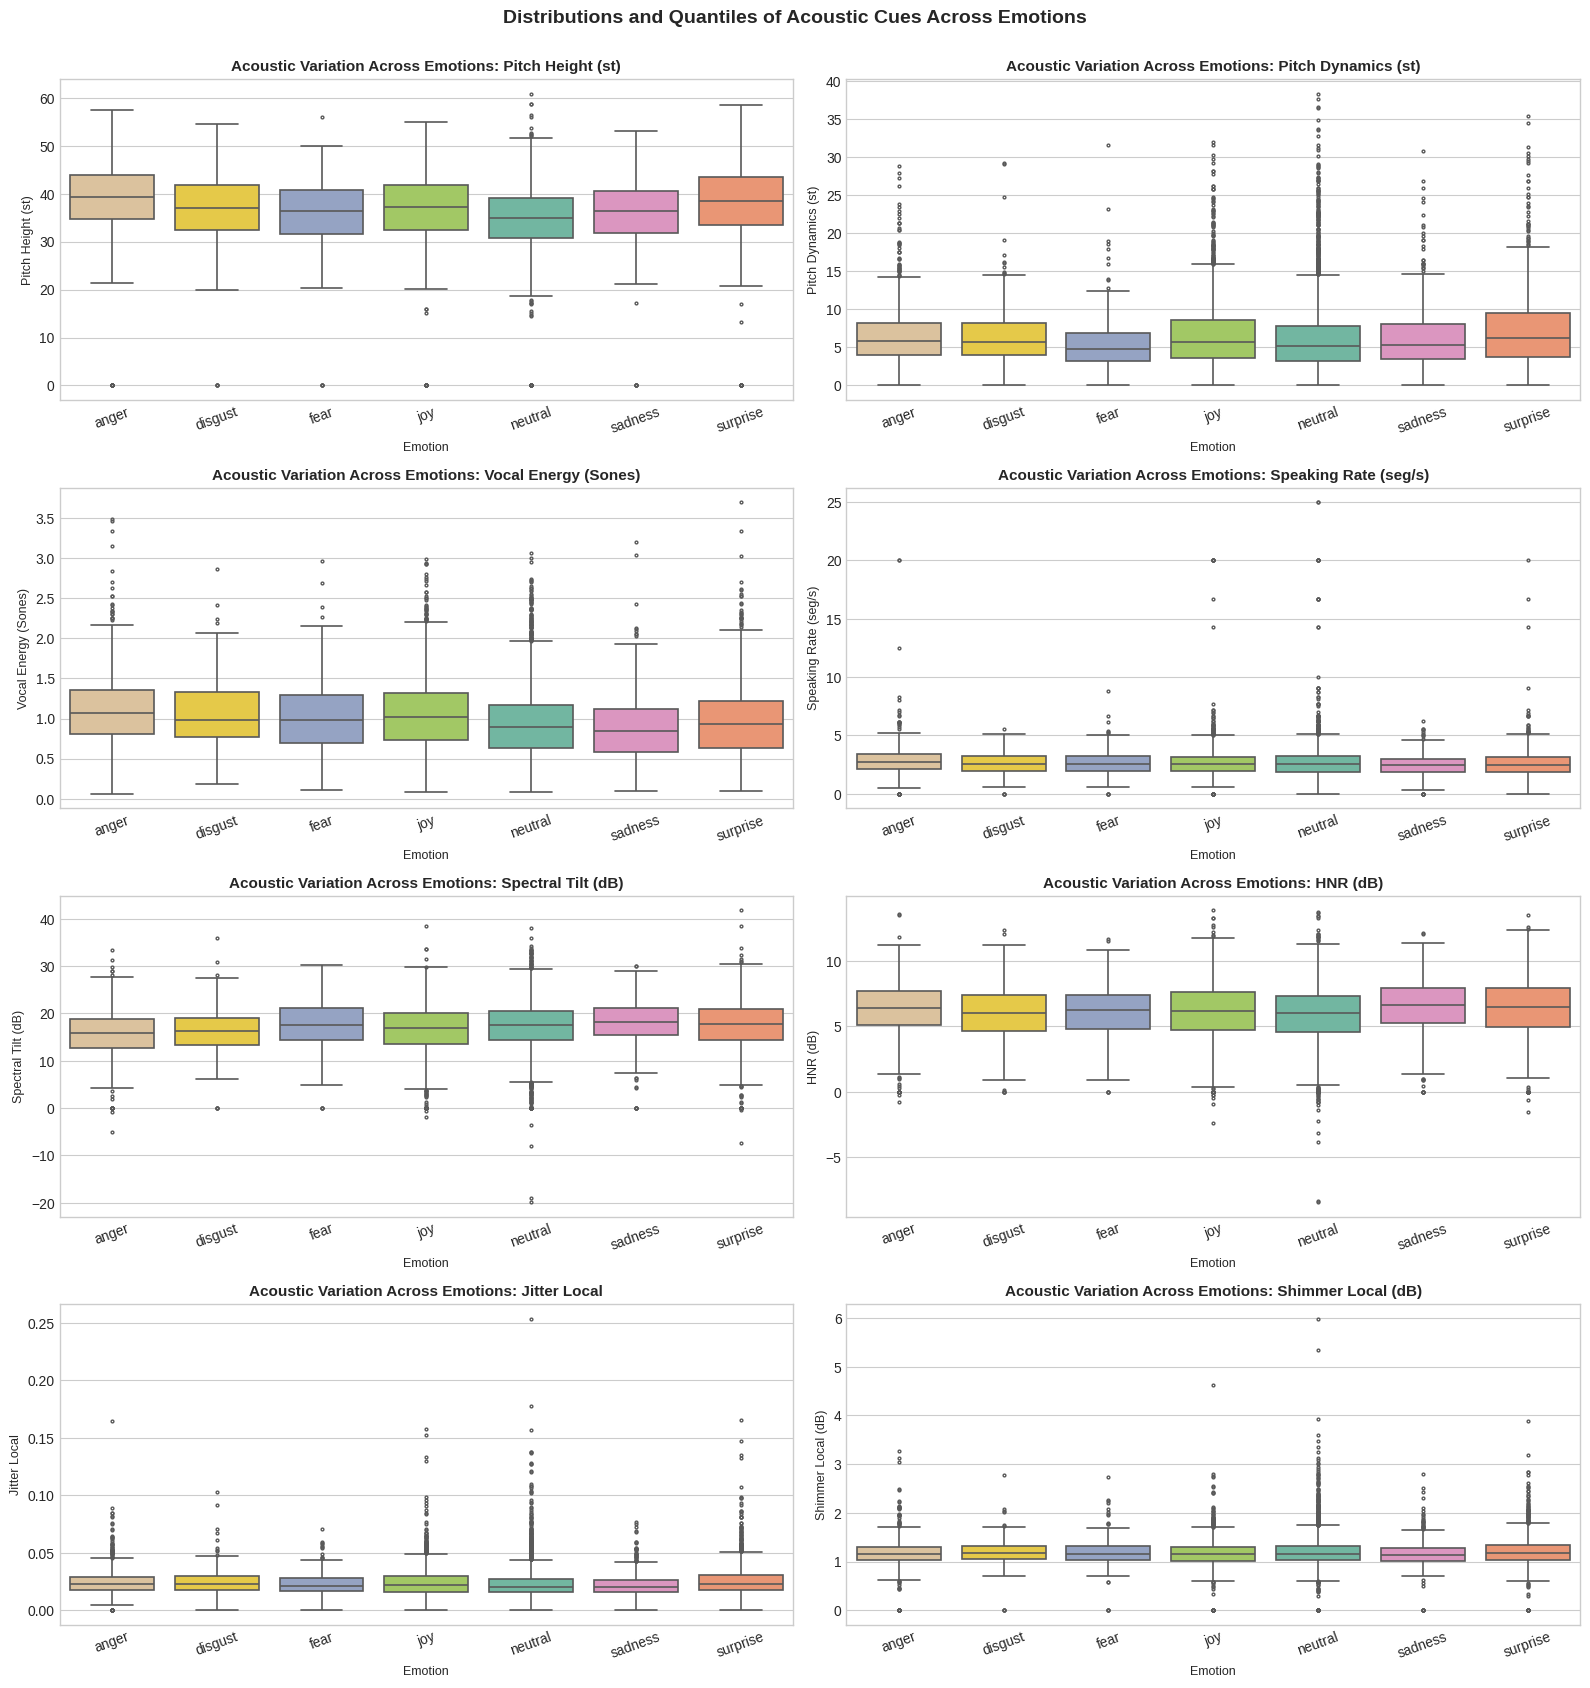

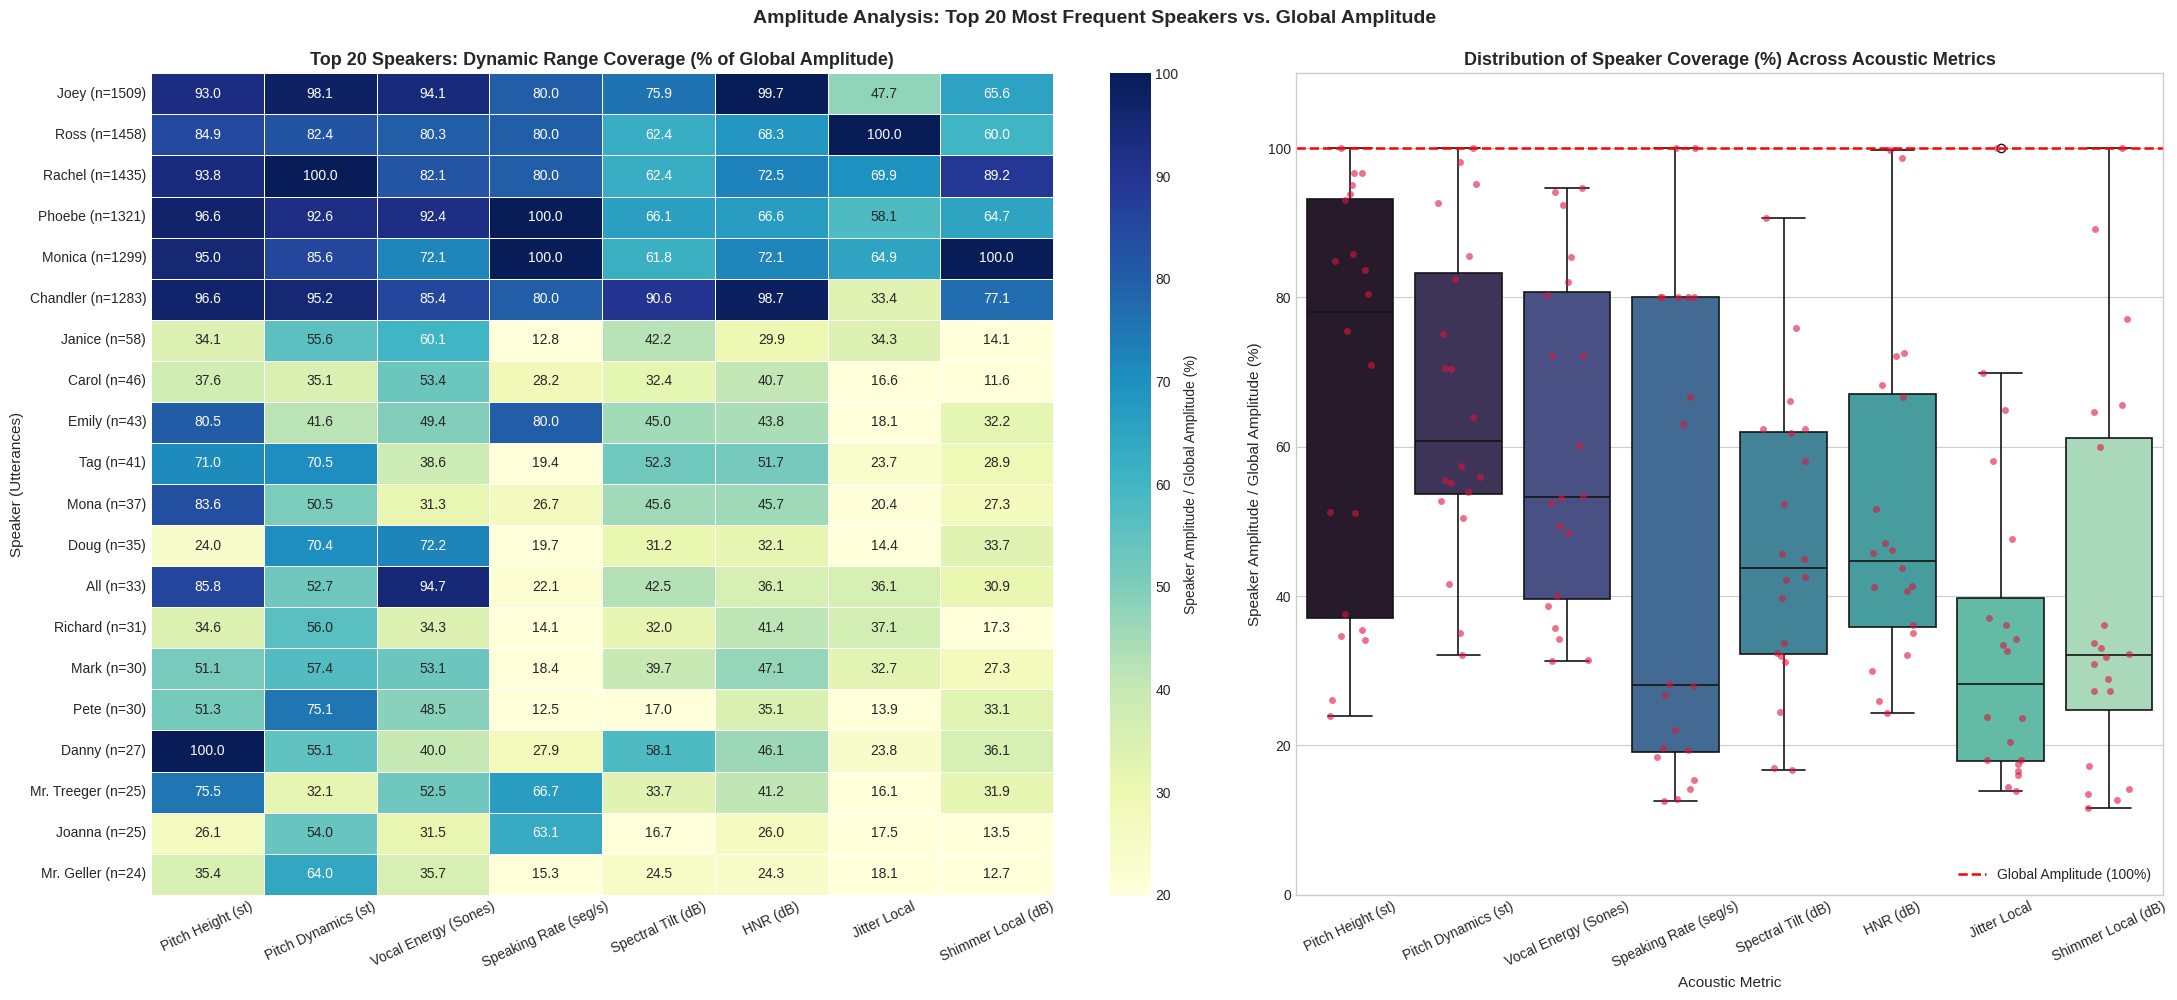

In [18]:
# ==============================================================================
# Diagnóstico de Variação por Emoção e Amplitudes dos Locutores (Raw Train Set)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

def analyze_emotion_and_speaker_acoustics(
    df: pd.DataFrame,
    top_n_speakers: int = 20,
    cues_dict: Dict[str, str] = ACOUSTIC_CUES,
):
    active_cues = {label: col for label, col in cues_dict.items() if col in df.columns}
    if not active_cues:
        print("⚠️ Nenhuma das colunas de cues acústicos foi encontrada no DataFrame.")
        return

    print("=" * 90)
    print("📊 DIAGNÓSTICO ACÚSTICO: VARIAÇÃO POR EMOÇÃO, QUANTIS E AMPLITUDES (LOCUTORES VS GLOBAL)")
    print("=" * 90)

    # A. AMPLITUDE E QUANTIS GLOBAIS (Full Corpus)
    global_rows = []
    global_amps = {}
    for label, col in active_cues.items():
        s = df[col].dropna()
        q10, q25, q33, q50, q66, q75, q90 = s.quantile([0.10, 0.25, 0.33, 0.50, 0.66, 0.75, 0.90])
        min_v, max_v = s.min(), s.max()
        amp = max_v - min_v
        global_amps[label] = amp
        global_rows.append({
            "Metric": label,
            "Count": len(s),
            "Mean": round(s.mean(), 2),
            "Std": round(s.std(), 2),
            "Min": round(min_v, 2),
            "Q10": round(q10, 2),
            "Q25": round(q25, 2),
            "Q33": round(q33, 2),
            "Median (Q50)": round(q50, 2),
            "Q66": round(q66, 2),
            "Q75": round(q75, 2),
            "Q90": round(q90, 2),
            "Max": round(max_v, 2),
            "Global Amplitude": round(amp, 2),
            "Global IQR": round(q75 - q25, 2),
        })

    df_global = pd.DataFrame(global_rows).set_index("Metric")

    # B. VARIAÇÃO DE EMOÇÃO E NÚMEROS DOS CUES ACÚSTICOS EM QUANTIS
    emo_rows = []
    for emo, emo_df in df.groupby("emotion"):
        for label, col in active_cues.items():
            s = emo_df[col].dropna()
            if len(s) == 0:
                continue
            q10, q25, q33, q50, q66, q75, q90 = s.quantile([0.10, 0.25, 0.33, 0.50, 0.66, 0.75, 0.90])
            min_v, max_v = s.min(), s.max()
            emo_rows.append({
                "Emotion": emo,
                "Metric": label,
                "Utterances": len(s),
                "Mean": round(s.mean(), 2),
                "Std": round(s.std(), 2),
                "Min": round(min_v, 2),
                "Q25": round(q25, 2),
                "Q33": round(q33, 2),
                "Median (Q50)": round(q50, 2),
                "Q66": round(q66, 2),
                "Q75": round(q75, 2),
                "Max": round(max_v, 2),
                "Amplitude": round(max_v - min_v, 2),
                "IQR": round(q75 - q25, 2),
            })

    df_emotion_quantiles = pd.DataFrame(emo_rows)

    # C. AMPLITUDE DOS 20 LOCUTORES COM MAIS FALAS (TOP 20 UTTERANCE SPEAKERS)
    spk_counts = df["speaker"].value_counts()
    top_speakers = spk_counts.head(top_n_speakers).index.tolist()

    spk_amp_rows = []
    spk_ratio_rows = []

    for spk in top_speakers:
        sub = df[df["speaker"] == spk]
        n_utt = len(sub)
        amp_entry = {"Speaker": spk, "Utterances": n_utt}
        ratio_entry = {"Speaker": f"{spk} (n={n_utt})"}

        for label, col in active_cues.items():
            s = sub[col].dropna()
            g_amp = global_amps.get(label, 0)
            if len(s) > 1:
                s_amp = s.max() - s.min()
                amp_entry[label] = round(s_amp, 2)
                ratio_entry[label] = round((s_amp / g_amp) * 100, 1) if g_amp > 0 else 0.0
            else:
                amp_entry[label] = 0.0
                ratio_entry[label] = 0.0

        spk_amp_rows.append(amp_entry)
        spk_ratio_rows.append(ratio_entry)

    df_top20_amplitudes = pd.DataFrame(spk_amp_rows).set_index("Speaker")
    df_top20_relative_amplitudes = pd.DataFrame(spk_ratio_rows).set_index("Speaker")

    # Adiciona estatísticas agregadas dos locutores à tabela global
    metric_cols = [c for c in df_top20_amplitudes.columns if c != "Utterances"]
    df_global["Mean Speaker Amp"] = [
        round(df_top20_amplitudes[m].mean(), 2) for m in df_global.index if m in metric_cols
    ]
    df_global["Speaker/Global Amp (%)"] = [
        round((df_top20_amplitudes[m].mean() / df_global.loc[m, "Global Amplitude"]) * 100, 1)
        for m in df_global.index if m in metric_cols
    ]

    # D. EXIBIÇÃO DE RESULTADOS
    print("\n1️⃣ QUANTIS E AMPLITUDE GLOBAL POR CUE ACÚSTICO (CORPUS COMPLETO):")
    display(df_global[["Min", "Q25", "Q33", "Median (Q50)", "Q66", "Q75", "Max", "Global Amplitude", "Global IQR", "Mean Speaker Amp", "Speaker/Global Amp (%)"]])

    print("\n2️⃣ VARIAÇÃO DE EMOÇÕES NOS QUANTIS E AMPLITUDES DOS CUES ACÚSTICOS:")
    display(df_emotion_quantiles.head(16))

    print(f"\n3️⃣ AMPLITUDES ABSOLUTAS (MAX - MIN) DOS {top_n_speakers} LOCUTORES COM MAIS FALAS:")
    display(df_top20_amplitudes)

    print(f"\n4️⃣ COBERTURA DA AMPLITUDE GLOBAL (%) PELOS {top_n_speakers} LOCUTORES COM MAIS FALAS:")
    display(df_top20_relative_amplitudes)

    # --------------------------------------------------------------------------
    # 4. PLOTS
    # --------------------------------------------------------------------------
    print("\n" + "=" * 90)
    print("📈 GERANDO VISUALIZAÇÕES DOS QUANTIS E AMPLITUDES...")
    print("=" * 90)

    # FIGURA 1: Variação das Emoções por Cue Acústico (Boxplots com Quantis)
    n_cues = len(active_cues)
    cols = 2
    rows = (n_cues + cols - 1) // cols

    plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
    fig1, axes1 = plt.subplots(rows, cols, figsize=(16, 4.2 * rows))
    axes1 = np.array(axes1).flatten()
    emo_order = sorted(df["emotion"].unique())

    for idx, (label, col) in enumerate(active_cues.items()):
        ax = axes1[idx]
        sns.boxplot(
            data=df,
            x="emotion",
            y=col,
            order=emo_order,
            hue="emotion",
            legend=False,
            palette="Set2",
            ax=ax,
            fliersize=2,
            linewidth=1.2,
        )
        ax.set_title(f"Acoustic Variation Across Emotions: {label}", fontsize=11, fontweight="bold")
        ax.set_xlabel("Emotion", fontsize=9)
        ax.set_ylabel(label, fontsize=9)
        ax.tick_params(axis="x", rotation=20)

    for idx in range(len(active_cues), len(axes1)):
        fig1.delaxes(axes1[idx])

    fig1.suptitle("Distributions and Quantiles of Acoustic Cues Across Emotions", fontsize=14, fontweight="bold", y=1.002)
    plt.tight_layout()
    plt.show()

    # FIGURA 2: Comparação de Amplitude dos Locutores vs Amplitude Global
    fig2, (ax_heat, ax_dist) = plt.subplots(1, 2, figsize=(22, 10), gridspec_kw={"width_ratios": [1.3, 1]})

    # Subplot A: Heatmap com percentual de amplitude global coberto
    sns.heatmap(
        df_top20_relative_amplitudes,
        annot=True,
        fmt=".1f",
        cmap="YlGnBu",
        cbar_kws={"label": "Speaker Amplitude / Global Amplitude (%)"},
        vmin=20,
        vmax=100,
        ax=ax_heat,
        linewidths=0.5,
    )
    ax_heat.set_title(f"Top {top_n_speakers} Speakers: Dynamic Range Coverage (% of Global Amplitude)", fontsize=13, fontweight="bold")
    ax_heat.set_ylabel("Speaker (Utterances)", fontsize=11)
    ax_heat.tick_params(axis="x", rotation=25)

    # Subplot B: Distribuição da cobertura relativa por métrica acústica
    df_melted_ratio = df_top20_relative_amplitudes.melt(var_name="Metric", value_name="Relative Amplitude (%)")
    sns.boxplot(
        data=df_melted_ratio,
        x="Metric",
        y="Relative Amplitude (%)",
        hue="Metric",
        legend=False,
        palette="mako",
        ax=ax_dist,
        linewidth=1.2,
    )
    sns.stripplot(
        data=df_melted_ratio,
        x="Metric",
        y="Relative Amplitude (%)",
        color="crimson",
        alpha=0.6,
        jitter=0.2,
        size=5,
        ax=ax_dist,
    )
    ax_dist.axhline(100.0, color="red", linestyle="--", linewidth=1.8, label="Global Amplitude (100%)")
    ax_dist.set_ylim(0, 110)
    ax_dist.set_title("Distribution of Speaker Coverage (%) Across Acoustic Metrics", fontsize=13, fontweight="bold")
    ax_dist.set_xlabel("Acoustic Metric", fontsize=11)
    ax_dist.set_ylabel("Speaker Amplitude / Global Amplitude (%)", fontsize=11)
    ax_dist.tick_params(axis="x", rotation=25)
    ax_dist.legend(loc="lower right", fontsize=10)

    fig2.suptitle(f"Amplitude Analysis: Top {top_n_speakers} Most Frequent Speakers vs. Global Amplitude", fontsize=14, fontweight="bold", y=0.995)
    plt.tight_layout()
    plt.show()

    return {
        "global_summary": df_global,
        "emotion_quantiles": df_emotion_quantiles,
        "speaker_amplitudes": df_top20_amplitudes,
        "speaker_relative_amplitudes": df_top20_relative_amplitudes,
    }

# Executa o diagnóstico completo sobre raw_train_set
acoustic_analysis_results = analyze_emotion_and_speaker_acoustics(raw_train_set, top_n_speakers=20)

## Balanced

In [19]:
import pandas as pd
from pathlib import Path
import librosa


def get_audio_duration(audio_path: str) -> float | None:
    """Return audio duration in seconds, or None if the file cannot be read."""
    try:
        return librosa.get_duration(path=audio_path)
    except Exception:
        return None


def sample_balanced_meld(
    df: pd.DataFrame,
    target_total: int = 2000,
    max_neutral_pct: float = 0.15,
    min_duration: float = 0.5,
    max_duration: float = 30.0,
    seed: int = 42,
) -> pd.DataFrame:
    """
    Create a deterministic, emotion-balanced MELD subset.

    Filtering:
        - Removes missing/invalid audio files.
        - Removes audio shorter than min_duration.
        - Removes audio longer than max_duration.

    Balancing:
        - Caps neutral at max_neutral_pct.
        - Distributes remaining samples across non-neutral emotions.
        - Redistributes unused quotas from underrepresented classes.

    Args:
        df: MELD dataframe containing 'audio_path' and 'emotion'.
        target_total: Desired number of samples.
        max_neutral_pct: Maximum proportion of neutral samples.
        min_duration: Minimum audio duration in seconds.
        max_duration: Maximum audio duration in seconds.
        seed: Random seed for deterministic sampling.

    Returns:
        Balanced and filtered DataFrame.
    """

    df = df.copy()

    # ----------------------------------------------------------
    # 1. Deterministic ordering
    # ----------------------------------------------------------

    id_cols = [
        c for c in ["dialogue", "utterance"]
        if c in df.columns
    ]

    if id_cols:
        df = df.sort_values(id_cols)
    elif "audio_path" in df.columns:
        df = df.sort_values("audio_path")

    df = df.reset_index(drop=True)

    # ----------------------------------------------------------
    # 2. Validate audio paths
    # ----------------------------------------------------------

    if "audio_path" not in df.columns:
        raise ValueError("DataFrame must contain 'audio_path'.")

    df = df[
        df["audio_path"].notna()
        & df["audio_path"].apply(
            lambda p: Path(str(p)).is_file()
        )
    ].copy()

    print(f"After audio validation: {len(df):,}")

    # ----------------------------------------------------------
    # 3. Audio duration filtering
    # ----------------------------------------------------------

    print("Computing audio durations...")

    df["duration"] = df["audio_path"].apply(get_audio_duration)

    failed_duration = df["duration"].isna().sum()

    if failed_duration:
        print(
            f"Warning: could not determine duration for "
            f"{failed_duration:,} files."
        )

    df = df[df["duration"].notna()].copy()

    df = df[
        df["duration"].between(
            min_duration,
            max_duration,
            inclusive="both",
        )
    ].copy()

    print(
        f"Duration filter: "
        f"{min_duration:.1f}s–{max_duration:.1f}s"
    )
    print(f"After duration filtering: {len(df):,}")

    # ----------------------------------------------------------
    # 4. Normalize emotion labels
    # ----------------------------------------------------------

    df["emotion"] = (
        df["emotion"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    df = df[df["emotion"].ne("nan")].copy()

    emotions = sorted(df["emotion"].unique())

    if not emotions:
        raise ValueError("No valid emotion classes remain.")

    print("\nAvailable emotions:")
    print(emotions)

    # ----------------------------------------------------------
    # 5. Cap neutral
    # ----------------------------------------------------------

    max_neutral_count = int(
        target_total * max_neutral_pct
    )

    non_neutral = [
        emotion
        for emotion in emotions
        if emotion != "neutral"
    ]

    # If neutral is not present, all samples go to
    # non-neutral classes.
    neutral_target = (
        min(
            max_neutral_count,
            len(df[df["emotion"] == "neutral"])
        )
        if "neutral" in emotions
        else 0
    )

    remaining_slots = target_total - neutral_target

    # ----------------------------------------------------------
    # 6. Initial non-neutral quotas
    # ----------------------------------------------------------

    quotas = {}

    if non_neutral:
        base = remaining_slots // len(non_neutral)
        remainder = remaining_slots % len(non_neutral)

        for i, emotion in enumerate(non_neutral):
            quotas[emotion] = (
                base + (1 if i < remainder else 0)
            )

    if "neutral" in emotions:
        quotas["neutral"] = neutral_target

    # ----------------------------------------------------------
    # 7. Redistribute unavailable samples
    # ----------------------------------------------------------

    while True:
        deficit = 0
        saturated = set()

        for emotion, quota in quotas.items():
            available = (
                df["emotion"].eq(emotion).sum()
            )

            if available < quota:
                deficit += quota - available
                quotas[emotion] = available
                saturated.add(emotion)

        if deficit == 0:
            break

        eligible = [
            emotion
            for emotion in non_neutral
            if emotion not in saturated
            and quotas[emotion]
            < df["emotion"].eq(emotion).sum()
        ]

        if not eligible:
            break

        base_extra = deficit // len(eligible)
        remainder = deficit % len(eligible)

        for i, emotion in enumerate(eligible):
            quotas[emotion] += (
                base_extra
                + (1 if i < remainder else 0)
            )

    # ----------------------------------------------------------
    # 8. Deterministic sampling
    # ----------------------------------------------------------

    sampled = []

    for emotion in sorted(quotas):
        n = quotas[emotion]

        if n == 0:
            continue

        class_df = df[df["emotion"] == emotion]

        sampled.append(
            class_df.sample(
                n=n,
                random_state=seed,
                replace=False,
            )
        )

    if not sampled:
        raise ValueError(
            "No samples available after filtering."
        )

    result = pd.concat(
        sampled,
        ignore_index=True,
    )

    # ----------------------------------------------------------
    # 9. Final deterministic ordering
    # ----------------------------------------------------------

    if id_cols:
        result = result.sort_values(id_cols)

    result = result.reset_index(drop=True)

    # ----------------------------------------------------------
    # 10. Diagnostics
    # ----------------------------------------------------------

    print("\n" + "=" * 50)
    print("MELD SAMPLING SUMMARY")
    print("=" * 50)

    print(f"Requested samples: {target_total:,}")
    print(f"Returned samples:  {len(result):,}")

    print("\nEmotion distribution:")
    print(result["emotion"].value_counts())

    print("\nEmotion proportions:")
    print(
        result["emotion"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
        .astype(str)
        .add("%")
    )

    print("\nAudio duration:")
    print(
        result["duration"].describe()[
            ["min", "mean", "max"]
        ].round(2)
    )

    print("\nQuotas:")
    print(quotas)

    return result

In [20]:
pruned_train_set = sample_balanced_meld(
    raw_train_set,
    target_total=2000,
    max_neutral_pct=0.15,
    min_duration=0.5,
    max_duration=30.0,
    seed=42,
)

run_test = sample_balanced_meld(
    raw_train_set,
    target_total=2000,
    max_neutral_pct=0.15,
    min_duration=0.5,
    max_duration=30.0,
    seed=42,
)

assert pruned_train_set.equals(run_test)

print("\nFinal candidate pool:")
display(pruned_train_set.head())

After audio validation: 9,988
Computing audio durations...
Duration filter: 0.5s–30.0s
After duration filtering: 9,681

Available emotions:
['anger', 'disgust', 'fear', 'joy', 'neutral', 'sadness', 'surprise']

MELD SAMPLING SUMMARY
Requested samples: 2,000
Returned samples:  2,000

Emotion distribution:
emotion
neutral     300
anger       293
joy         292
sadness     291
surprise    291
disgust     268
fear        265
Name: count, dtype: int64

Emotion proportions:
emotion
neutral      15.0%
anger       14.65%
joy          14.6%
sadness     14.55%
surprise    14.55%
disgust      13.4%
fear        13.25%
Name: proportion, dtype: object

Audio duration:
min      0.51
mean     3.33
max     22.95
Name: duration, dtype: float64

Quotas:
{'anger': np.int64(293), 'disgust': np.int64(268), 'fear': np.int64(265), 'joy': np.int64(292), 'sadness': np.int64(291), 'surprise': np.int64(291), 'neutral': 300}
After audio validation: 9,988
Computing audio durations...
Duration filter: 0.5s–30.0s
Af

,audio_path,time,utterance,dialogue,emotion,text,speaker,F0semitoneFrom27.5Hz_sma3nz_amean,F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2,loudness_sma3_percentile50.0,VoicedSegmentsPerSec,hammarbergIndexV_sma3nz_amean,HNRdBACF_sma3nz_amean,jitterLocal_sma3nz_amean,shimmerLocaldB_sma3nz_amean,duration
0,/content/MELD/preprocessed_train_splits/dia0_u...,2.219,9,0,neutral,We can go into detail,The Interviewer,28.810305,2.902483,0.755903,2.803739,19.237234,6.250984,0.015701,1.070284,2.218688
1,/content/MELD/preprocessed_train_splits/dia0_u...,2.005,10,0,fear,No dont I beg of you!,Chandler,33.925426,8.947289,1.143961,2.061856,13.352987,3.297102,0.023200,1.292880,2.005375
2,/content/MELD/preprocessed_train_splits/dia1_u...,2.475,0,1,surprise,But then who? The waitress I went out with las...,Joey,28.792513,1.474661,1.225475,2.489627,18.477812,4.619659,0.012924,1.324144,2.474687
3,/content/MELD/preprocessed_train_splits/dia1_u...,2.219,1,1,sadness,You know? Forget it!,Rachel,37.167171,6.227909,0.617221,1.860465,20.580799,5.719617,0.051611,1.371788,2.218688
4,/content/MELD/preprocessed_train_splits/dia1_u...,4.757,2,1,surprise,"No-no-no-no, no! Who, who were you talking about?",Joey,36.927811,9.820950,1.009611,3.411514,18.723021,4.865646,0.037674,1.331839,4.757375


In [21]:
from sklearn.model_selection import train_test_split

In [22]:
train_set, val_set = train_test_split(
    pruned_train_set,
    test_size=0.2,
    random_state=42,
    stratify=pruned_train_set["emotion"],
)

In [23]:
train_set['emotion'].value_counts()

,count
emotion,
neutral,240
joy,234
anger,234
sadness,233
surprise,233
disgust,214
fear,212


In [24]:
train_set['speaker'].value_counts()

,count
speaker,
Rachel,246
Joey,244
Phoebe,222
Chandler,215
Monica,214
...,...
Rachel and Phoebe,1
Another Scientist,1
Janine,1


In [25]:
display(train_set)

,audio_path,time,utterance,dialogue,emotion,text,speaker,F0semitoneFrom27.5Hz_sma3nz_amean,F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2,loudness_sma3_percentile50.0,VoicedSegmentsPerSec,hammarbergIndexV_sma3nz_amean,HNRdBACF_sma3nz_amean,jitterLocal_sma3nz_amean,shimmerLocaldB_sma3nz_amean,duration
1760,/content/MELD/preprocessed_train_splits/dia921...,0.704,5,921,sadness,No-no its not!,Eric,31.504700,1.594723,0.971907,3.125000,28.355448,8.076351,0.011920,1.028892,0.704000
1341,/content/MELD/preprocessed_train_splits/dia698...,1.835,3,698,disgust,Noo.,Rachel,43.353996,2.817863,0.210902,1.129943,23.570908,12.043491,0.012698,0.748850,1.834688
469,/content/MELD/preprocessed_train_splits/dia237...,4.011,9,237,sadness,"I'm sorry, my friend Phoebe...",Monica,36.626148,8.339176,0.487151,2.531646,13.571520,5.918450,0.074552,1.235459,4.010688
1264,/content/MELD/preprocessed_train_splits/dia655...,5.227,9,655,surprise,Really?,Ross,31.756283,2.790981,0.504608,1.550388,25.658468,6.632182,0.018136,1.112266,5.226687
1731,/content/MELD/preprocessed_train_splits/dia907...,3.925,9,907,disgust,Save it Red! Unless you wanna spend the night ...,Phoebe,41.575012,3.678955,1.220119,2.590674,14.828059,6.169218,0.019418,1.146574,3.925375
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
576,/content/MELD/preprocessed_train_splits/dia283...,3.520,6,283,disgust,"Okay, whatever.",Phoebe,31.701672,11.846041,0.939283,2.890173,17.290997,4.739032,0.031922,1.250546,3.520000
1328,/content/MELD/preprocessed_train_splits/dia688...,2.603,0,688,neutral,"Youve seen my huge stack of porn, right?",Joey,33.543880,6.975632,1.214611,3.149606,15.151702,5.205800,0.015217,1.105613,2.602688
1979,/content/MELD/preprocessed_train_splits/dia103...,2.091,1,1030,sadness,Is this about me taking your watch?,Chloe,38.013603,1.759830,0.917641,3.448276,23.780550,9.723830,0.011484,0.872821,2.090688
870,/content/MELD/preprocessed_train_splits/dia445...,3.349,3,445,fear,"All right here he comes. Im gonna do this, I...",Rachel,32.740173,3.986284,0.785044,3.658537,19.804991,5.518298,0.024809,1.166903,3.349375


### 2.2 Balanceamento do Subconjunto dos 6 Locutores Principais (GRPO)

Para garantir o alinhamento rigoroso entre as recompensas de inventário acústico (R2) e as trajetórias de treinamento GRPO:
1. **Exclusividade dos 6 Personagens Principais**: O conjunto de treino é restrito aos 6 locutores com maior volume de falas (`Joey`, `Ross`, `Rachel`, `Phoebe`, `Monica`, `Chandler`).
2. **Prevenção Estrita de Data Leakage**: Nenhum arquivo de áudio presente no conjunto de validação (`val_set` com 400 amostras) é incluído no treino (sobreposição = 0%).
3. **Recorte Temporal Dialógico**: Áudios com duração estritamente entre **1.0 segundo e 20.0 segundos** (respeitando a distribuição natural de diálogos no MELD).
4. **Recorte de Integridade eGeMAPS**: Descarte estrito de áudios com medições acústicas zeradas (`0.0`) ou nulas (especialmente F0, segmentos vozeados, loudness, jitter e shimmer), impedindo ruído de extração.
5. **Estratificação de Emoções e Falantes**: Teto máximo de 15% para a classe `neutral`, distribuição equilibrada entre as classes emocionais e divisão proporcional entre os 6 locutores.


In [26]:
# ==============================================================================
# Balanceamento Específico para os 6 Locutores Principais (GRPO Train Set)
# ==============================================================================
from typing import Dict, List, Optional
import pandas as pd
import numpy as np

TOP_6_SPEAKERS = ["Joey", "Ross", "Rachel", "Phoebe", "Monica", "Chandler"]

STRICTLY_POSITIVE_ACOUSTIC_FEATURES = [
    "F0semitoneFrom27.5Hz_sma3nz_amean",
    "F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2",
    "loudness_sma3_percentile50.0",
    "VoicedSegmentsPerSec",
    "jitterLocal_sma3nz_amean",
    "shimmerLocaldB_sma3nz_amean",
]

ALL_ACOUSTIC_COLS = STRICTLY_POSITIVE_ACOUSTIC_FEATURES + [
    "HNRdBACF_sma3nz_amean",
    "hammarbergIndexV_sma3nz_amean",
]


def sample_balanced_top_speakers(
    train_df: pd.DataFrame,
    val_df: Optional[pd.DataFrame] = None,
    top_speakers: Optional[List[str]] = None,
    min_duration: float = 1.0,
    max_duration: float = 20.0,
    max_neutral_pct: float = 0.15,
    target_total: Optional[int] = None,
    seed: int = 42,
) -> pd.DataFrame:
    """Extrai um subconjunto balanceado exclusivamente dos 6 locutores principais.

    Garante exclusão estrita dos 400 áudios de validação, limites de duração (1.0s-20.0s)
    e filtro rigoroso contra métricas acústicas eGeMAPS zeradas ou nulas.
    """
    df = train_df.copy()

    # 1. Exclusão estrita dos áudios do conjunto de validação
    if val_df is not None and "audio_path" in val_df.columns and "audio_path" in df.columns:
        val_paths = set(val_df["audio_path"].dropna().astype(str))
        init_len = len(df)
        df = df[~df["audio_path"].astype(str).isin(val_paths)].copy()
        print(f"🔒 Exclusão de validação: {init_len - len(df)} áudios coincidentes removidos.")

    # 2. Filtragem exclusiva para os 6 locutores calibrados
    target_speakers = top_speakers or TOP_6_SPEAKERS
    if "speaker" in df.columns:
        df = df[df["speaker"].isin(target_speakers)].copy()
        print(f"👥 Filtrado para os {len(target_speakers)} locutores principais: {len(df)} amostras disponíveis.")

    # 3. Recorte temporal (1.0s a 20.0s)
    dur_col = "duration" if "duration" in df.columns else ("time" if "time" in df.columns else None)
    if dur_col is not None:
        df = df[df[dur_col].notna()].copy()
        df = df[df[dur_col].between(min_duration, max_duration, inclusive="both")].copy()
        print(f"⏱️ Recorte temporal [{min_duration}s, {max_duration}s]: {len(df)} amostras.")

    # 4. Recorte eGeMAPS: métricas de áudio não podem estar zeradas nem nulas
    for col in ALL_ACOUSTIC_COLS:
        if col in df.columns:
            df = df[df[col].notna() & (df[col] != 0.0)].copy()
            if col in STRICTLY_POSITIVE_ACOUSTIC_FEATURES:
                df = df[df[col] > 0.0].copy()
    print(f"🎙️ Recorte eGeMAPS (métricas estritamente não zeradas): {len(df)} amostras válidas.")

    # 5. Normalização de emoções e cálculo de cotas
    if "emotion" in df.columns:
        df["emotion"] = df["emotion"].astype(str).str.strip().str.lower()
    emotions = sorted(df["emotion"].unique())
    non_neutral = [e for e in emotions if e != "neutral"]

    if target_total is None or target_total > len(df):
        counts = df["emotion"].value_counts()
        min_non_neutral = min([counts.get(e, 0) for e in non_neutral]) if non_neutral else 0
        slots_non_neutral = min_non_neutral * len(non_neutral)
        neutral_avail = counts.get("neutral", 0)
        neutral_target = min(neutral_avail, int(slots_non_neutral * max_neutral_pct / (1.0 - max_neutral_pct)))
        target_total = slots_non_neutral + neutral_target

    max_neutral = int(target_total * max_neutral_pct)
    neutral_count = min(max_neutral, df["emotion"].eq("neutral").sum()) if "neutral" in emotions else 0
    remaining_slots = target_total - neutral_count

    quotas: Dict[str, int] = {}
    if non_neutral:
        base = remaining_slots // len(non_neutral)
        rem = remaining_slots % len(non_neutral)
        for i, emo in enumerate(non_neutral):
            quotas[emo] = base + (1 if i < rem else 0)
    if "neutral" in emotions:
        quotas["neutral"] = neutral_count

    # Redistribuição iterativa de cotas
    while True:
        deficit = 0
        saturated = set()
        for emo, quota in quotas.items():
            avail = df["emotion"].eq(emo).sum()
            if avail < quota:
                deficit += (quota - avail)
                quotas[emo] = avail
                saturated.add(emo)
        if deficit == 0:
            break
        eligible = [e for e in non_neutral if e not in saturated and quotas[e] < df["emotion"].eq(e).sum()]
        if not eligible:
            break
        base_extra = deficit // len(eligible)
        rem_extra = deficit % len(eligible)
        for i, emo in enumerate(eligible):
            quotas[emo] += base_extra + (1 if i < rem_extra else 0)

    # 6. Amostragem determinística estratificada por emoção e locutor
    sampled_dfs = []
    for emo, q in quotas.items():
        if q == 0:
            continue
        sub_emo = df[df["emotion"] == emo]
        spk_groups = []
        spk_quota = q // len(target_speakers)
        spk_rem = q % len(target_speakers)

        for s_idx, spk in enumerate(sorted(target_speakers)):
            spk_df = sub_emo[sub_emo["speaker"] == spk]
            needed = spk_quota + (1 if s_idx < spk_rem else 0)
            take = min(needed, len(spk_df))
            if take > 0:
                spk_groups.append(spk_df.sample(n=take, random_state=seed, replace=False))

        sampled_emo = pd.concat(spk_groups) if spk_groups else pd.DataFrame()
        if len(sampled_emo) < q:
            missing = q - len(sampled_emo)
            already_idx = set(sampled_emo.index)
            remaining_pool = sub_emo[~sub_emo.index.isin(already_idx)]
            if len(remaining_pool) > 0:
                fill = remaining_pool.sample(n=min(missing, len(remaining_pool)), random_state=seed, replace=False)
                sampled_emo = pd.concat([sampled_emo, fill])

        sampled_dfs.append(sampled_emo)

    result = pd.concat(sampled_dfs, ignore_index=True)
    id_cols = [c for c in ["dialogue", "utterance"] if c in result.columns]
    if id_cols:
        result = result.sort_values(id_cols)
    elif "audio_path" in result.columns:
        result = result.sort_values("audio_path")
    result = result.reset_index(drop=True)

    return result


# Executa a amostragem balanceada apenas nos 6 locutores principais
grpo_train_set = sample_balanced_top_speakers(
    train_df=train_set,
    val_df=val_set,
    top_speakers=TOP_6_SPEAKERS,
    min_duration=1.0,
    max_duration=20.0,
    max_neutral_pct=0.15,
    seed=42,
)

# Atualiza train_set para que todas as etapas seguintes utilizem o dataset balanceado dos 6 locutores
train_set = grpo_train_set

print(f"\n🎯 Conjunto balanceado final para GRPO: {len(train_set)} amostras.")
print(f"Locutores presentes: {sorted(train_set['speaker'].unique())}")
if "audio_path" in val_set.columns and "audio_path" in train_set.columns:
    overlap = set(train_set["audio_path"]).intersection(set(val_set["audio_path"]))
    assert len(overlap) == 0, f"Erro: {len(overlap)} áudios do conjunto de validação vazaram para o treino!"
    print("🔒 Integridade verificada: 0 vazamento de áudios entre treino e validação.")

print("\nDistribuição por Emoção:")
display(train_set["emotion"].value_counts())
print("\nDistribuição por Locutor:")
display(train_set["speaker"].value_counts())


🔒 Exclusão de validação: 0 áudios coincidentes removidos.
👥 Filtrado para os 6 locutores principais: 1346 amostras disponíveis.
⏱️ Recorte temporal [1.0s, 20.0s]: 1256 amostras.
🎙️ Recorte eGeMAPS (métricas estritamente não zeradas): 1250 amostras válidas.

🎯 Conjunto balanceado final para GRPO: 1129 amostras.
Locutores presentes: ['Chandler', 'Joey', 'Monica', 'Phoebe', 'Rachel', 'Ross']
🔒 Integridade verificada: 0 vazamento de áudios entre treino e validação.

Distribuição por Emoção:


,count
emotion,
neutral,169
surprise,160
fear,160
disgust,160
sadness,160
anger,160
joy,160



Distribuição por Locutor:


,count
speaker,
Joey,201
Rachel,192
Chandler,188
Monica,184
Ross,183
Phoebe,181


### 2.3 Construção do Conjunto Disjunto para SFT (`sft_train_eval`: 350 Amostras Balanceadas) e Split Estratificado 80/20 (280 Treino / 70 Avaliação)

Para construir o estágio de **Supervised Fine-Tuning (SFT)** utilizando exclusivamente os dados brutos (`raw_train_set`) que **não** pertencem ao conjunto de treino desenhado para o GRPO (`grpo_train_set`):
1. **Exclusão Estrita do Treino GRPO (`0% Leakage`)**:
   Remove todas as amostras presentes no `grpo_train_set` ($1.129$ amostras), verificando tanto `audio_path` quanto o par `(dialogue, utterance)` (e prioriza amostras que também não estejam no `val_set`).
2. **Amostragem Totalmente Balanceada (`350` exemplos = `50` por emoção $\times 7$ classes)**:
   - Prioriza os 6 locutores principais (`Joey`, `Ross`, `Rachel`, `Phoebe`, `Monica`, `Chandler`) com duração em $[1.0\text{s}, 20.0\text{s}]$ e métricas eGeMAPS estritamente não zeradas, rotacionando o resto da divisão entre as emoções para manter equilíbrio entre locutores.
   - Nas emoções minoritárias do MELD (`disgust` e `fear`, cujas falas dos 6 protagonistas no treino já foram alocadas ao `grpo_train_set`), completa a cota exata de `50` exemplos com os demais locutores válidos do `raw_train_set`.
3. **Divisão Estratificada 80/20 por Emoção e Locutor (`train_test_split`)**:
   Divide as `350` amostras em **`sft_train_set` (`280` amostras: `40` por emoção)** e **`sft_eval_set` (`70` amostras: `10` por emoção)** estratificando simultaneamente por **emoção e locutor**.

In [27]:
# ==============================================================================
# Construção do Conjunto SFT Disjunto (350 Amostras) e Split 80/20 (280 / 70)
# ==============================================================================
from typing import Dict, List, Optional, Tuple
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

TOP_6_SPEAKERS = ["Joey", "Ross", "Rachel", "Phoebe", "Monica", "Chandler"]

STRICTLY_POSITIVE_ACOUSTIC_FEATURES = [
    "F0semitoneFrom27.5Hz_sma3nz_amean",
    "F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2",
    "loudness_sma3_percentile50.0",
    "VoicedSegmentsPerSec",
    "jitterLocal_sma3nz_amean",
    "shimmerLocaldB_sma3nz_amean",
]

ALL_ACOUSTIC_COLS = STRICTLY_POSITIVE_ACOUSTIC_FEATURES + [
    "HNRdBACF_sma3nz_amean",
    "hammarbergIndexV_sma3nz_amean",
]


def _make_utterance_keys(df: pd.DataFrame) -> set:
    """Cria chaves únicas por (dialogue, utterance) e audio_path para bloqueio de vazamento."""
    keys = set()
    if "audio_path" in df.columns:
        keys.update(df["audio_path"].dropna().astype(str).tolist())
    if "dialogue" in df.columns and "utterance" in df.columns:
        for d, u in zip(df["dialogue"], df["utterance"]):
            if pd.notna(d) and pd.notna(u):
                keys.add(f"dia_{int(d)}_utt_{int(u)}")
    return keys


def _filter_out_keys(df: pd.DataFrame, forbidden_keys: set) -> pd.DataFrame:
    """Remove qualquer linha cujo audio_path ou par (dialogue, utterance) pertença a forbidden_keys."""
    mask = pd.Series(True, index=df.index)
    if "audio_path" in df.columns:
        mask &= ~df["audio_path"].astype(str).isin(forbidden_keys)
    if "dialogue" in df.columns and "utterance" in df.columns:
        dia_utt = [
            f"dia_{int(d)}_utt_{int(u)}" if (pd.notna(d) and pd.notna(u)) else ""
            for d, u in zip(df["dialogue"], df["utterance"])
        ]
        mask &= ~pd.Series(dia_utt, index=df.index).isin(forbidden_keys)
    return df[mask].copy()


def sample_sft_disjoint_balanced(
    raw_df: pd.DataFrame,
    grpo_df: pd.DataFrame,
    grpo_val_df: Optional[pd.DataFrame] = None,
    top_speakers: Optional[List[str]] = None,
    target_total: int = 350,
    min_duration: float = 1.0,
    max_duration: float = 20.0,
    fallback_min_duration: float = 0.5,
    fallback_max_duration: float = 30.0,
    seed: int = 42,
) -> pd.DataFrame:
    """Extrai um conjunto de 350 amostras 100% balanceadas (50 por emoção) para SFT,
    estritamente disjunto do conjunto de treino do GRPO (grpo_df).

    Prioridade de amostragem por emoção (cota = 50 por classe):
      1. Amostras fora do grpo_df (e fora do grpo_val_df) pertencentes aos 6 locutores principais
         (TOP_6_SPEAKERS) com duração em [1.0s, 20.0s] e eGeMAPS não zerado, distribuídas
         uniformemente entre os 6 locutores.
      2. Demais locutores fora do grpo_df (e fora do grpo_val_df) com duração em [1.0s, 20.0s]
         e eGeMAPS não zerado, priorizando locutores recorrentes.
      3. Fallback suave de duração [0.5s, 30.0s] fora do grpo_df (priorizando amostras fora do
         grpo_val_df) caso alguma emoção rara ('disgust'/'fear') precise completar as 50 amostras.
    """
    target_speakers = top_speakers or TOP_6_SPEAKERS
    df = raw_df.copy()

    # 1. Exclusão estrita e inegociável de todas as amostras do GRPO Train
    grpo_train_keys = _make_utterance_keys(grpo_df)
    grpo_val_keys = _make_utterance_keys(grpo_val_df) if grpo_val_df is not None else set()

    init_len = len(df)
    df = _filter_out_keys(df, grpo_train_keys)
    print(f"🔒 Exclusão estrita do GRPO Train: {init_len - len(df)} amostras removidas ({len(df)} restantes no raw_train_set).")

    # Pool primário também exclui grpo_val_df sempre que houver amostras suficientes
    df_no_val = _filter_out_keys(df, grpo_val_keys) if grpo_val_keys else df.copy()
    print(f"🔒 Pool primário (fora do GRPO Train e fora do GRPO Val): {len(df_no_val)} amostras disponíveis.")

    # 2. Normalização dos rótulos de emoção
    for sub in (df, df_no_val):
        sub["emotion"] = sub["emotion"].astype(str).str.strip().str.lower()
    df = df[df["emotion"].notna() & (df["emotion"] != "nan")].copy()
    df_no_val = df_no_val[df_no_val["emotion"].notna() & (df_no_val["emotion"] != "nan")].copy()

    emotions = sorted(df["emotion"].unique())
    n_classes = len(emotions)
    assert target_total % n_classes == 0, f"target_total ({target_total}) deve ser múltiplo de {n_classes}."
    quota_per_emotion = target_total // n_classes

    # 3. Máscara de duração e validade estrita eGeMAPS
    def _build_pools(source_df: pd.DataFrame) -> Tuple[pd.DataFrame, pd.DataFrame]:
        dur_col = "duration" if "duration" in source_df.columns else ("time" if "time" in source_df.columns else None)
        valid_egemaps = pd.Series(True, index=source_df.index)
        for col in ALL_ACOUSTIC_COLS:
            if col in source_df.columns:
                valid_egemaps &= source_df[col].notna() & (source_df[col] != 0.0)
                if col in STRICTLY_POSITIVE_ACOUSTIC_FEATURES:
                    valid_egemaps &= (source_df[col] > 0.0)
        if dur_col is not None:
            s_dur = source_df[dur_col].notna() & source_df[dur_col].between(min_duration, max_duration, inclusive="both")
            r_dur = source_df[dur_col].notna() & source_df[dur_col].between(fallback_min_duration, fallback_max_duration, inclusive="both")
        else:
            s_dur = pd.Series(True, index=source_df.index)
            r_dur = pd.Series(True, index=source_df.index)
        return source_df[s_dur & valid_egemaps].copy(), source_df[r_dur & valid_egemaps].copy()

    strict_no_val, relaxed_no_val = _build_pools(df_no_val)
    strict_all, relaxed_all = _build_pools(df)

    sampled_emotions: List[pd.DataFrame] = []

    for emo_idx, emo in enumerate(emotions):
        emo_strict = strict_no_val[strict_no_val["emotion"] == emo]
        emo_top6 = emo_strict[emo_strict["speaker"].isin(target_speakers)]

        # Rotaciona a ordem dos 6 locutores a cada emoção para distribuir o resto (50 % 6 = 2)
        rot_offset = emo_idx % len(target_speakers)
        rotated_speakers = target_speakers[rot_offset:] + target_speakers[:rot_offset]

        spk_parts: List[pd.DataFrame] = []
        base_q = quota_per_emotion // len(target_speakers)
        rem_q = quota_per_emotion % len(target_speakers)

        for s_i, spk in enumerate(rotated_speakers):
            spk_sub = emo_top6[emo_top6["speaker"] == spk]
            needed = base_q + (1 if s_i < rem_q else 0)
            take = min(needed, len(spk_sub))
            if take > 0:
                spk_parts.append(spk_sub.sample(n=take, random_state=seed + emo_idx, replace=False))

        emo_selected = pd.concat(spk_parts) if spk_parts else pd.DataFrame(columns=df.columns)

        # Preenche com outros locutores do Top-6 dentro do pool estrito (sem val)
        if len(emo_selected) < quota_per_emotion:
            rem_top6 = emo_top6[~emo_top6.index.isin(emo_selected.index)]
            if len(rem_top6) > 0:
                take_extra = min(quota_per_emotion - len(emo_selected), len(rem_top6))
                emo_selected = pd.concat([
                    emo_selected,
                    rem_top6.sample(n=take_extra, random_state=seed + emo_idx, replace=False)
                ])

        # Tier 2: Demais locutores no recorte estrito [1.0s, 20.0s] + eGeMAPS válido (sem val),
        # priorizando locutores com mais amostras para favorecer a estratificação 80/20
        if len(emo_selected) < quota_per_emotion:
            rem_other_strict = emo_strict[~emo_strict.index.isin(emo_selected.index)].copy()
            if len(rem_other_strict) > 0:
                spk_freq = rem_other_strict["speaker"].value_counts()
                rem_other_strict = rem_other_strict.assign(
                    _spk_cnt=rem_other_strict["speaker"].map(spk_freq),
                    _rand=np.random.default_rng(seed + emo_idx).random(len(rem_other_strict)),
                ).sort_values(["_spk_cnt", "speaker", "_rand"], ascending=[False, True, True])
                take_other = min(quota_per_emotion - len(emo_selected), len(rem_other_strict))
                emo_selected = pd.concat([
                    emo_selected,
                    rem_other_strict.iloc[:take_other].drop(columns=["_spk_cnt", "_rand"])
                ])

        # Tier 3: Cascatas de fallback estritamente fora do grpo_train_set
        fallback_pools = [
            relaxed_no_val[relaxed_no_val["emotion"] == emo],
            df_no_val[df_no_val["emotion"] == emo],
            strict_all[strict_all["emotion"] == emo],
            relaxed_all[relaxed_all["emotion"] == emo],
            df[df["emotion"] == emo],
        ]
        for fb_pool in fallback_pools:
            if len(emo_selected) >= quota_per_emotion:
                break
            rem_fb = fb_pool[~fb_pool.index.isin(emo_selected.index)]
            if len(rem_fb) > 0:
                take_fb = min(quota_per_emotion - len(emo_selected), len(rem_fb))
                emo_selected = pd.concat([
                    emo_selected,
                    rem_fb.sample(n=take_fb, random_state=seed + emo_idx, replace=False)
                ])

        assert len(emo_selected) == quota_per_emotion, (
            f"Emoção '{emo}' obteve {len(emo_selected)} amostras (esperado {quota_per_emotion})."
        )
        sampled_emotions.append(emo_selected)

    sft_df = pd.concat(sampled_emotions, ignore_index=True)
    id_cols = [c for c in ["dialogue", "utterance"] if c in sft_df.columns]
    if id_cols:
        sft_df = sft_df.sort_values(id_cols)
    elif "audio_path" in sft_df.columns:
        sft_df = sft_df.sort_values("audio_path")
    sft_df = sft_df.reset_index(drop=True)
    return sft_df


def build_emotion_speaker_strata(df: pd.DataFrame) -> pd.Series:
    """Constrói a chave composta (emotion, speaker) para o train_test_split(test_size=0.20).

    Agrupa blocos de múltiplos de 5 por (emotion, speaker) e consolida locutores minoritários
    (< 5 amostras naquela emoção) em blocos ordenados por locutor de tamanho 5.
    Isso garante matematicamente:
      1. Zero erro de classe unitária (ValueError) no train_test_split do scikit-learn;
      2. Divisão 80/20 100% exata por emoção (40 treino / 10 validação em cada uma das 7 emoções);
      3. Preservação estrita da proporção 80/20 de cada locutor entre treino e validação.
    """
    strata = pd.Series(index=df.index, dtype=str)
    for emo, grp in df.groupby("emotion"):
        spk_counts = grp["speaker"].value_counts()
        remainder_indices: List[int] = []
        for spk, cnt in spk_counts.items():
            spk_idx = grp[grp["speaker"] == spk].index.tolist()
            k5 = (cnt // 5) * 5
            if k5 >= 5:
                for b_id, start in enumerate(range(0, k5, 5)):
                    for idx in spk_idx[start : start + 5]:
                        strata.loc[idx] = f"{emo}__{spk}_blk{b_id}"
                remainder_indices.extend(spk_idx[k5:])
            else:
                remainder_indices.extend(spk_idx)

        for chunk_id, start in enumerate(range(0, len(remainder_indices), 5)):
            chunk = remainder_indices[start : start + 5]
            tag = f"{emo}__REM_GRP_{chunk_id}" if len(chunk) == 5 else f"{emo}__REM_GRP_0"
            for idx in chunk:
                strata.loc[idx] = tag
    return strata


# 1. Preserva referência explícita ao grpo_train_set (1129 amostras) e val_set (400 amostras)
grpo_reference_train = grpo_train_set.copy()
grpo_reference_val = val_set.copy() if "val_set" in globals() else None

# 2. Extrai as 350 amostras 100% balanceadas do raw_train_set fora do GRPO Train
sft_train_eval = sample_sft_disjoint_balanced(
    raw_df=raw_train_set,
    grpo_df=grpo_reference_train,
    grpo_val_df=grpo_reference_val,
    top_speakers=TOP_6_SPEAKERS,
    target_total=350,
    min_duration=1.0,
    max_duration=20.0,
    seed=42,
)

# 3. Aplica train_test_split (80/20 -> 280 SFT Train / 70 SFT Eval) estratificado por emoção e locutor
sft_train_eval["emotion_speaker_stratum"] = build_emotion_speaker_strata(sft_train_eval)

sft_train_set, sft_eval_set = train_test_split(
    sft_train_eval,
    test_size=0.20,
    random_state=42,
    stratify=sft_train_eval["emotion_speaker_stratum"],
)

sft_train_set = sft_train_set.drop(columns=["emotion_speaker_stratum"]).reset_index(drop=True)
sft_eval_set = sft_eval_set.drop(columns=["emotion_speaker_stratum"]).reset_index(drop=True)
sft_train_eval = sft_train_eval.drop(columns=["emotion_speaker_stratum"]).reset_index(drop=True)

print("=" * 75)
print(f"✅ Split SFT Concluído: Total = {len(sft_train_eval)} | SFT Train (80%) = {len(sft_train_set)} | SFT Eval (20%) = {len(sft_eval_set)}")
print("=" * 75)

summary_split_df = pd.DataFrame({
    "SFT Total (350)": sft_train_eval["emotion"].value_counts(),
    "SFT Train 80% (280)": sft_train_set["emotion"].value_counts(),
    "SFT Eval 20% (70)": sft_eval_set["emotion"].value_counts(),
    "Proporção Train (%)": (sft_train_set["emotion"].value_counts(normalize=True) * 100).round(2),
    "Proporção Eval (%)": (sft_eval_set["emotion"].value_counts(normalize=True) * 100).round(2),
})
display(summary_split_df)

🔒 Exclusão estrita do GRPO Train: 1129 amostras removidas (8859 restantes no raw_train_set).
🔒 Pool primário (fora do GRPO Train e fora do GRPO Val): 8459 amostras disponíveis.
✅ Split SFT Concluído: Total = 350 | SFT Train (80%) = 280 | SFT Eval (20%) = 70


,SFT Total (350),SFT Train 80% (280),SFT Eval 20% (70),Proporção Train (%),Proporção Eval (%)
emotion,,,,,
anger,50,40,10,14.29,14.29
disgust,50,40,10,14.29,14.29
fear,50,40,10,14.29,14.29
joy,50,40,10,14.29,14.29
neutral,50,40,10,14.29,14.29
sadness,50,40,10,14.29,14.29
surprise,50,40,10,14.29,14.29


### 2.4 Avaliação e Auditoria do Split (Vazamento Zero, Distribuição de Locutores e Quantis Acústicos)

Esta célula executa a validação científica completa da separação entre **GRPO** e **SFT**:
1. **Verificação de Vazamento Zero (`0% Leakage`)**: Audita a disjunção estrita entre `GRPO Train`, `SFT Train (280)` e `SFT Eval (70)` (e verifica também contra `GRPO Val`), tanto por `audio_path` quanto por `(dialogue, utterance)`.
2. **Diferença de Locutores (`GRPO Train` vs. `SFT Train` / `SFT Eval`)**: Compara a representatividade dos 6 locutores principais (`Joey`, `Ross`, `Rachel`, `Phoebe`, `Monica`, `Chandler`) e demais locutores, calculando a Distância Total de Variação ($\text{TVD}$) e a Divergência de Jensen-Shannon ($\text{JSD}$), além de detalhar a cobertura por emoção.
3. **Diferença nos Quantis dos Cues Acústicos ($Q_{25}, Q_{50}, Q_{75}, \text{IQR}$)**: Avalia os desvios absolutos e relativos nos quantis globais e individuais por locutor entre `GRPO Train` e `SFT Train`, executa o teste não-paramétrico de Kolmogorov-Smirnov ($\text{KS}$) e mede a taxa de concordância de classificação discreta (`low`, `moderate`, `high`).

1️⃣ AUDITORIA DE VAZAMENTO DE DADOS (SFT vs. GRPO)


,Tamanho A,Tamanho B,Overlap audio_path,"Overlap (dialogue, utterance)",Status
Par de Splits Auditado,,,,,
GRPO Train ↔ SFT Total (350),1129,350,0,0,✅ 0 Vazamento (100% Disjunto)
GRPO Train ↔ SFT Train (280),1129,280,0,0,✅ 0 Vazamento (100% Disjunto)
GRPO Train ↔ SFT Eval (70),1129,70,0,0,✅ 0 Vazamento (100% Disjunto)
SFT Train (280) ↔ SFT Eval (70),280,70,0,0,✅ 0 Vazamento (100% Disjunto)
GRPO Val (400) ↔ SFT Train (280),400,280,0,0,✅ 0 Vazamento (100% Disjunto)
GRPO Val (400) ↔ SFT Eval (70),400,70,0,0,✅ 0 Vazamento (100% Disjunto)


🔒 Asserções de disjunção entre SFT Train, SFT Eval e GRPO Train verificadas com sucesso (0 vazamento)!

2️⃣ COMPARAÇÃO DA DISTRIBUIÇÃO DE LOCUTORES (GRPO TRAIN vs. SFT TRAIN & EVAL)


,GRPO Train (N),GRPO Train (%),SFT Train (N),SFT Train (%),SFT Eval (N),SFT Eval (%),Δ% Global (SFT Train - GRPO),Δ% Intra-Top6 (SFT - GRPO)
Locutor / Grupo,,,,,,,,
Joey,201,17.80,38,13.57,8,11.43,-4.23,-1.14
Ross,183,16.21,33,11.79,10,14.29,-4.42,-1.74
Rachel,192,17.01,39,13.93,9,12.86,-3.08,0.10
Phoebe,181,16.03,34,12.14,10,14.29,-3.89,-1.12
Monica,184,16.30,44,15.71,11,15.71,-0.58,3.00
Chandler,188,16.65,40,14.29,10,14.29,-2.37,0.89
Outros Locutores (Fora do Top 6),0,0.00,52,18.57,12,17.14,18.57,NaN


📊 Distância Total de Variação (TVD) Global [GRPO Train vs SFT Train]: 0.1857 (JSD = 0.2648)
📊 Distância Total de Variação (TVD) Intra-Top6 [GRPO Train vs SFT Train]: 0.0399 (Equilíbrio entre os 6 protagonistas)
📊 Distância Total de Variação (TVD) [SFT Train 80% vs SFT Eval 20%]: 0.0465 (Fidelidade da estratificação 80/20)

🔍 Cobertura dos 6 Locutores Principais por Emoção no SFT Train (280 amostras):


...

,GRPO Q25,SFT Q25,Δ Q25 (%),GRPO Mediana,SFT Mediana,GRPO Q75,SFT Q75,Δ Q75 (%),GRPO IQR,SFT IQR,KS Stat (p-val)
Cue Acústico,,,,,,,,,,,
pitch_height,32.768,32.799,+0.031 (+0.1%),37.316,36.677,41.908,40.387,-1.520 (-3.6%),9.139,7.588,0.075 (p=0.15)
pitch_dynamics,3.814,3.862,+0.048 (+1.3%),5.634,5.994,8.339,8.327,-0.013 (-0.2%),4.525,4.464,0.062 (p=0.34)
vocal_energy,0.724,0.698,-0.026 (-3.6%),0.980,0.932,1.252,1.233,-0.019 (-1.5%),0.528,0.535,0.072 (p=0.18)
speaking_rate,1.955,1.994,+0.039 (+2.0%),2.514,2.568,3.172,3.226,+0.053 (+1.7%),1.217,1.232,0.070 (p=0.21)
jitter,0.017,0.016,-0.001 (-4.7%),0.022,0.021,0.028,0.028,+0.000 (+0.2%),0.011,0.012,0.046 (p=0.71)
shimmer,1.038,1.050,+0.011 (+1.1%),1.160,1.162,1.293,1.289,-0.004 (-0.3%),0.255,0.239,0.026 (p=1.00)
hnr,5.181,4.912,-0.269 (-5.2%),6.503,6.326,7.713,7.485,-0.228 (-3.0%),2.532,2.573,0.069 (p=0.22)
hammarberg,14.665,14.157,-0.509 (-3.5%),17.579,17.263,20.360,20.100,-0.260 (-1.3%),5.695,5.943,0.063 (p=0.32)



📌 B. Diferença nos Quantis por Locutor (Δ = SFT Train - GRPO Train) nos 4 Cues Prosódicos:


,N_GRPO,N_SFT_Train,pitch_height ΔQ25,pitch_height ΔQ75,pitch_dynamics ΔQ25,pitch_dynamics ΔQ75,vocal_energy ΔQ25,vocal_energy ΔQ75,speaking_rate ΔQ25,speaking_rate ΔQ75
Speaker,,,,,,,,,,
Joey,201,38,0.13,-0.74,0.43,-0.69,-0.04,0.09,0.14,0.12
Ross,183,33,-1.02,-2.45,-0.03,0.69,0.03,-0.05,-0.47,-0.40
Rachel,192,39,-0.50,-0.65,-0.46,-0.55,-0.14,-0.16,0.16,0.19
Phoebe,181,34,0.10,-0.89,-1.24,-2.56,-0.07,-0.17,-0.34,-0.10
Monica,184,44,0.24,-1.27,1.06,0.72,-0.03,-0.08,0.09,-0.06
Chandler,188,40,0.36,-0.09,0.12,2.06,0.03,0.04,0.03,0.00



📌 C. Concordância de Rótulo Discreto (Low / Moderate / High) entre Quantis GRPO vs. Quantis SFT:


,Amostras Válidas (SFT Train),Concordância Exata de Tier (GRPO Q vs SFT Q)
Dimensão Acústica,,
pitch_height,280,92.86% (260/280)
pitch_dynamics,280,87.86% (246/280)
vocal_energy,280,91.43% (256/280)
speaking_rate,280,91.43% (256/280)
jitter,280,89.64% (251/280)
shimmer,280,85.36% (239/280)
hnr,280,90.71% (254/280)
hammarberg,280,90.36% (253/280)


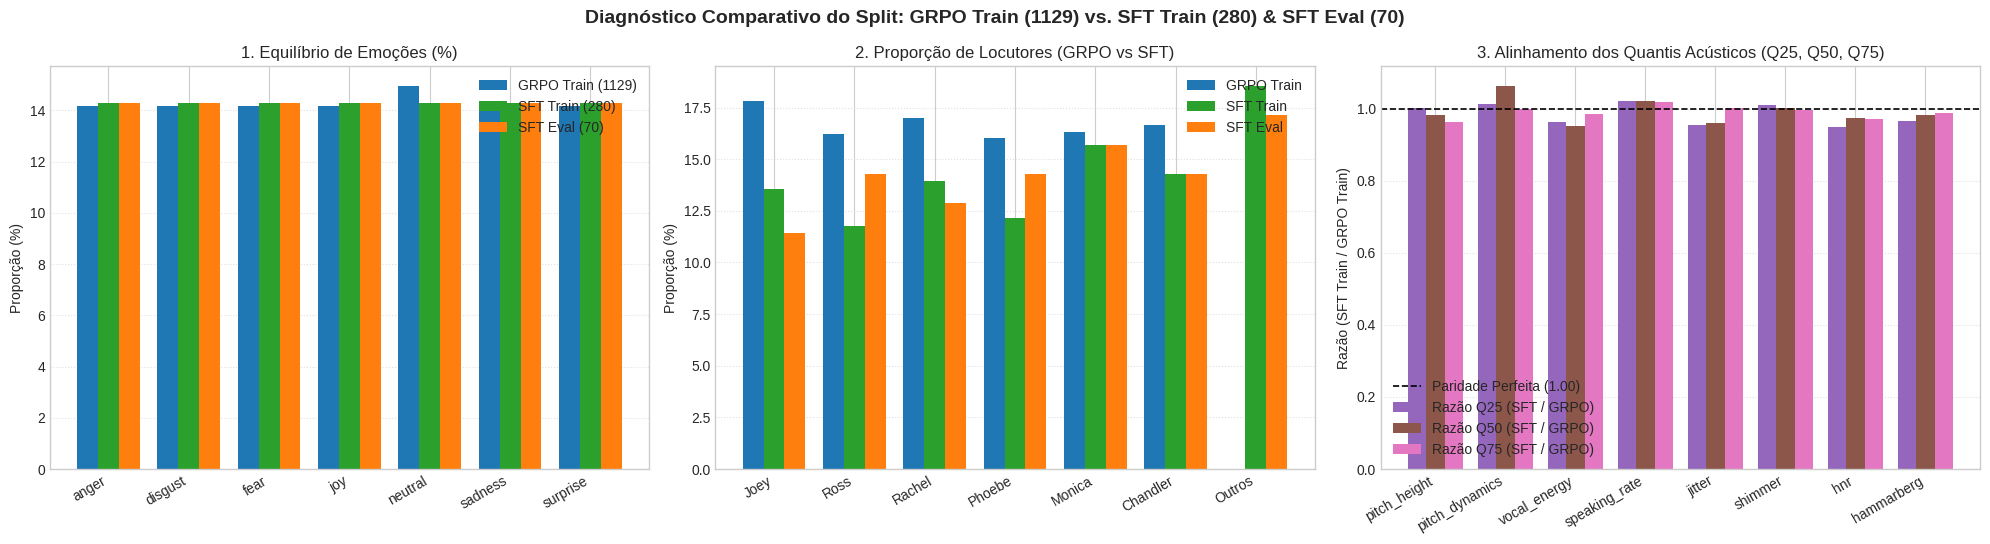

In [28]:
# ==============================================================================
# Avaliação Completa do Split: Vazamento (SFT vs GRPO), Locutores e Quantis Acústicos
# ==============================================================================
from scipy.stats import ks_2samp
from scipy.spatial.distance import jensenshannon
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

EVAL_ACOUSTIC_CUES: Dict[str, str] = {
    "pitch_height": "F0semitoneFrom27.5Hz_sma3nz_amean",
    "pitch_dynamics": "F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2",
    "vocal_energy": "loudness_sma3_percentile50.0",
    "speaking_rate": "VoicedSegmentsPerSec",
    "jitter": "jitterLocal_sma3nz_amean",
    "shimmer": "shimmerLocaldB_sma3nz_amean",
    "hnr": "HNRdBACF_sma3nz_amean",
    "hammarberg": "hammarbergIndexV_sma3nz_amean",
}


def compute_split_quantiles(
    df: pd.DataFrame,
    speakers: List[str] = TOP_6_SPEAKERS,
    cues_map: Dict[str, str] = EVAL_ACOUSTIC_CUES,
) -> Dict[str, Dict[str, Dict[str, float]]]:
    """Calcula Q25, Q50 (Mediana), Q75 e IQR por locutor e globalmente (__GLOBAL__)."""
    q_dict: Dict[str, Dict[str, Dict[str, float]]] = {}

    def _stats(series: pd.Series, col_name: str) -> Optional[Dict[str, float]]:
        s = series.dropna()
        s = s[s != 0.0]
        if col_name in STRICTLY_POSITIVE_ACOUSTIC_FEATURES:
            s = s[s > 0.0]
        if len(s) == 0:
            return None
        q25 = float(s.quantile(0.25))
        q50 = float(s.quantile(0.50))
        q75 = float(s.quantile(0.75))
        return {
            "q25": q25,
            "q50": q50,
            "q75": q75,
            "iqr": q75 - q25,
            "count": int(len(s)),
        }

    for spk in speakers:
        sub = df[df["speaker"] == spk]
        q_dict[spk] = {}
        for cue, col in cues_map.items():
            if col in sub.columns:
                st = _stats(sub[col], col)
                if st is not None:
                    q_dict[spk][cue] = st

    q_dict["__GLOBAL__"] = {}
    for cue, col in cues_map.items():
        if col in df.columns:
            st = _stats(df[col], col)
            if st is not None:
                q_dict["__GLOBAL__"][cue] = st

    return q_dict


# ------------------------------------------------------------------------------
# 1. VERIFICAÇÃO DE VAZAMENTO ZERO (LEAKAGE AUDIT) ENTRE SFT E GRPO
# ------------------------------------------------------------------------------
print("=" * 85)
print("1️⃣ AUDITORIA DE VAZAMENTO DE DADOS (SFT vs. GRPO)")
print("=" * 85)

critical_pairs = [
    ("GRPO Train", grpo_reference_train, "SFT Total (350)", sft_train_eval, True),
    ("GRPO Train", grpo_reference_train, "SFT Train (280)", sft_train_set, True),
    ("GRPO Train", grpo_reference_train, "SFT Eval (70)", sft_eval_set, True),
    ("SFT Train (280)", sft_train_set, "SFT Eval (70)", sft_eval_set, True),
]
if grpo_reference_val is not None:
    critical_pairs.extend([
        ("GRPO Val (400)", grpo_reference_val, "SFT Train (280)", sft_train_set, False),
        ("GRPO Val (400)", grpo_reference_val, "SFT Eval (70)", sft_eval_set, False),
    ])

leakage_rows = []
for name_a, df_a, name_b, df_b, strict_assert in critical_pairs:
    path_overlap = 0
    if "audio_path" in df_a.columns and "audio_path" in df_b.columns:
        path_overlap = len(
            set(df_a["audio_path"].dropna().astype(str)).intersection(
                set(df_b["audio_path"].dropna().astype(str))
            )
        )

    id_overlap = 0
    if {"dialogue", "utterance"}.issubset(df_a.columns) and {"dialogue", "utterance"}.issubset(df_b.columns):
        ids_a = set(zip(df_a["dialogue"], df_a["utterance"]))
        ids_b = set(zip(df_b["dialogue"], df_b["utterance"]))
        id_overlap = len(ids_a.intersection(ids_b))

    if strict_assert:
        assert path_overlap == 0 and id_overlap == 0, (
            f"ERRO CRÍTICO DE VAZAMENTO entre {name_a} e {name_b}: "
            f"{path_overlap} audio_paths e {id_overlap} pares (dialogue, utterance) em comum!"
        )
    leakage_rows.append({
        "Par de Splits Auditado": f"{name_a}  ↔  {name_b}",
        "Tamanho A": len(df_a),
        "Tamanho B": len(df_b),
        "Overlap audio_path": path_overlap,
        "Overlap (dialogue, utterance)": id_overlap,
        "Status": "✅ 0 Vazamento (100% Disjunto)" if (path_overlap == 0 and id_overlap == 0) else f"⚠️ {max(path_overlap, id_overlap)} em comum",
    })

display(pd.DataFrame(leakage_rows).set_index("Par de Splits Auditado"))
print("🔒 Asserções de disjunção entre SFT Train, SFT Eval e GRPO Train verificadas com sucesso (0 vazamento)!")

# ------------------------------------------------------------------------------
# 2. DIFERENÇA DE LOCUTORES ENTRE OS TREINOS (GRPO TRAIN vs. SFT TRAIN / EVAL)
# ------------------------------------------------------------------------------
print("\n" + "=" * 85)
print("2️⃣ COMPARAÇÃO DA DISTRIBUIÇÃO DE LOCUTORES (GRPO TRAIN vs. SFT TRAIN & EVAL)")
print("=" * 85)


def _speaker_group_series(df: pd.DataFrame) -> pd.Series:
    return df["speaker"].apply(lambda s: s if s in TOP_6_SPEAKERS else "Outros Locutores (Fora do Top 6)")


grpo_spk_cnt = _speaker_group_series(grpo_reference_train).value_counts()
sft_tr_spk_cnt = _speaker_group_series(sft_train_set).value_counts()
sft_ev_spk_cnt = _speaker_group_series(sft_eval_set).value_counts()

all_spk_groups = TOP_6_SPEAKERS + ["Outros Locutores (Fora do Top 6)"]
spk_comp_rows = []
for spk_g in all_spk_groups:
    g_c = int(grpo_spk_cnt.get(spk_g, 0))
    st_c = int(sft_tr_spk_cnt.get(spk_g, 0))
    se_c = int(sft_ev_spk_cnt.get(spk_g, 0))

    g_pct = (g_c / len(grpo_reference_train)) * 100.0
    st_pct = (st_c / len(sft_train_set)) * 100.0
    se_pct = (se_c / len(sft_eval_set)) * 100.0

    # Proporção apenas dentro do subconjunto Top-6
    g_top6_total = max(1, sum(int(grpo_spk_cnt.get(s, 0)) for s in TOP_6_SPEAKERS))
    st_top6_total = max(1, sum(int(sft_tr_spk_cnt.get(s, 0)) for s in TOP_6_SPEAKERS))
    g_top6_pct = (g_c / g_top6_total * 100.0) if spk_g in TOP_6_SPEAKERS else np.nan
    st_top6_pct = (st_c / st_top6_total * 100.0) if spk_g in TOP_6_SPEAKERS else np.nan

    spk_comp_rows.append({
        "Locutor / Grupo": spk_g,
        "GRPO Train (N)": g_c,
        "GRPO Train (%)": round(g_pct, 2),
        "SFT Train (N)": st_c,
        "SFT Train (%)": round(st_pct, 2),
        "SFT Eval (N)": se_c,
        "SFT Eval (%)": round(se_pct, 2),
        "Δ% Global (SFT Train - GRPO)": round(st_pct - g_pct, 2),
        "Δ% Intra-Top6 (SFT - GRPO)": round(st_top6_pct - g_top6_pct, 2) if pd.notna(g_top6_pct) else np.nan,
    })

spk_comp_df = pd.DataFrame(spk_comp_rows).set_index("Locutor / Grupo")
display(spk_comp_df)

# Métricas de distância distributiva de locutores
p_grpo_all = np.array([spk_comp_df.loc[s, "GRPO Train (%)"] / 100.0 for s in all_spk_groups])
p_sft_tr_all = np.array([spk_comp_df.loc[s, "SFT Train (%)"] / 100.0 for s in all_spk_groups])
p_sft_ev_all = np.array([spk_comp_df.loc[s, "SFT Eval (%)"] / 100.0 for s in all_spk_groups])

tvd_grpo_sft = 0.5 * float(np.abs(p_grpo_all - p_sft_tr_all).sum())
jsd_grpo_sft = float(jensenshannon(p_grpo_all, p_sft_tr_all))
tvd_sft_tr_ev = 0.5 * float(np.abs(p_sft_tr_all - p_sft_ev_all).sum())

p_grpo_top6 = np.array([grpo_spk_cnt.get(s, 0) for s in TOP_6_SPEAKERS], dtype=float)
p_grpo_top6 /= p_grpo_top6.sum()
p_sft_top6 = np.array([sft_tr_spk_cnt.get(s, 0) for s in TOP_6_SPEAKERS], dtype=float)
p_sft_top6 /= p_sft_top6.sum()
tvd_intra_top6 = 0.5 * float(np.abs(p_grpo_top6 - p_sft_top6).sum())

print(f"📊 Distância Total de Variação (TVD) Global [GRPO Train vs SFT Train]: {tvd_grpo_sft:.4f} (JSD = {jsd_grpo_sft:.4f})")
print(f"📊 Distância Total de Variação (TVD) Intra-Top6 [GRPO Train vs SFT Train]: {tvd_intra_top6:.4f} (Equilíbrio entre os 6 protagonistas)")
print(f"📊 Distância Total de Variação (TVD) [SFT Train 80% vs SFT Eval 20%]: {tvd_sft_tr_ev:.4f} (Fidelidade da estratificação 80/20)")

# Cobertura Top-6 vs Outros por Emoção no SFT Train
emo_spk_breakdown = pd.crosstab(
    sft_train_set["emotion"],
    sft_train_set["speaker"].apply(lambda s: "Top-6 Locutores" if s in TOP_6_SPEAKERS else "Outros Locutores"),
)
emo_spk_breakdown["Total SFT Train"] = emo_spk_breakdown.sum(axis=1)
if "Top-6 Locutores" in emo_spk_breakdown.columns:
    emo_spk_breakdown["Cobertura Top-6 (%)"] = (
        emo_spk_breakdown["Top-6 Locutores"] / emo_spk_breakdown["Total SFT Train"] * 100.0
    ).round(1)
print("\n🔍 Cobertura dos 6 Locutores Principais por Emoção no SFT Train (280 amostras):")
display(emo_spk_breakdown)

# ------------------------------------------------------------------------------
# 3. DIFERENÇA ENTRE OS QUANTIS ACÚSTICOS (GRPO TRAIN vs. SFT TRAIN)
# ------------------------------------------------------------------------------
print("\n" + "=" * 85)
print("3️⃣ AVALIAÇÃO DAS DIFERENÇAS NOS QUANTIS DOS CUES ACÚSTICOS (GRPO vs. SFT)")
print("=" * 85)

grpo_quantiles = compute_split_quantiles(grpo_reference_train)
sft_train_quantiles = compute_split_quantiles(sft_train_set)
sft_eval_quantiles = compute_split_quantiles(sft_eval_set)

# A. Comparação Global dos 8 Cues Físicos (Q25, Q50, Q75, IQR e Teste KS)
global_q_rows = []
for cue, col in EVAL_ACOUSTIC_CUES.items():
    if cue not in grpo_quantiles["__GLOBAL__"] or cue not in sft_train_quantiles["__GLOBAL__"]:
        continue
    gq = grpo_quantiles["__GLOBAL__"][cue]
    sq = sft_train_quantiles["__GLOBAL__"][cue]

    s_grpo = grpo_reference_train[col].dropna()
    s_grpo = s_grpo[s_grpo > 0.0] if col in STRICTLY_POSITIVE_ACOUSTIC_FEATURES else s_grpo[s_grpo != 0.0]
    s_sft = sft_train_set[col].dropna()
    s_sft = s_sft[s_sft > 0.0] if col in STRICTLY_POSITIVE_ACOUSTIC_FEATURES else s_sft[s_sft != 0.0]

    ks_stat, ks_pval = ks_2samp(s_grpo, s_sft)

    d_q25 = sq["q25"] - gq["q25"]
    d_q50 = sq["q50"] - gq["q50"]
    d_q75 = sq["q75"] - gq["q75"]
    rel_q25 = (d_q25 / abs(gq["q25"]) * 100.0) if gq["q25"] != 0 else 0.0
    rel_q75 = (d_q75 / abs(gq["q75"]) * 100.0) if gq["q75"] != 0 else 0.0

    global_q_rows.append({
        "Cue Acústico": cue,
        "GRPO Q25": round(gq["q25"], 3),
        "SFT Q25": round(sq["q25"], 3),
        "Δ Q25 (%)": f"{d_q25:+.3f} ({rel_q25:+.1f}%)",
        "GRPO Mediana": round(gq["q50"], 3),
        "SFT Mediana": round(sq["q50"], 3),
        "GRPO Q75": round(gq["q75"], 3),
        "SFT Q75": round(sq["q75"], 3),
        "Δ Q75 (%)": f"{d_q75:+.3f} ({rel_q75:+.1f}%)",
        "GRPO IQR": round(gq["iqr"], 3),
        "SFT IQR": round(sq["iqr"], 3),
        "KS Stat (p-val)": f"{ks_stat:.3f} (p={ks_pval:.2f})",
    })

global_q_df = pd.DataFrame(global_q_rows).set_index("Cue Acústico")
print("📌 A. Comparação Global dos Quantis (Q25, Mediana, Q75, IQR e Teste KS) [GRPO Train vs SFT Train]:")
display(global_q_df)

# B. Comparação por Locutor Principal (Top 6 Speakers) nos 4 Cues Prosódicos Primários
CORE_4_CUES = ["pitch_height", "pitch_dynamics", "vocal_energy", "speaking_rate"]
spk_q_rows = []
for spk in TOP_6_SPEAKERS:
    row = {
        "Speaker": spk,
        "N_GRPO": int((grpo_reference_train["speaker"] == spk).sum()),
        "N_SFT_Train": int((sft_train_set["speaker"] == spk).sum()),
    }
    for cue in CORE_4_CUES:
        if cue in grpo_quantiles.get(spk, {}) and cue in sft_train_quantiles.get(spk, {}):
            gq = grpo_quantiles[spk][cue]
            sq = sft_train_quantiles[spk][cue]
            row[f"{cue} ΔQ25"] = round(sq["q25"] - gq["q25"], 2)
            row[f"{cue} ΔQ75"] = round(sq["q75"] - gq["q75"], 2)
    spk_q_rows.append(row)

spk_q_df = pd.DataFrame(spk_q_rows).set_index("Speaker")
print("\n📌 B. Diferença nos Quantis por Locutor (Δ = SFT Train - GRPO Train) nos 4 Cues Prosódicos:")
display(spk_q_df)

# C. Taxa de Concordância de Classificação Discreta (Low / Moderate / High) no SFT Train
tier_agreement_rows = []
for cue, col in EVAL_ACOUSTIC_CUES.items():
    agree = 0
    total_valid = 0
    for _, r in sft_train_set.iterrows():
        val = r.get(col)
        if pd.isna(val) or val == 0.0 or (col in STRICTLY_POSITIVE_ACOUSTIC_FEATURES and val <= 0.0):
            continue
        spk = r["speaker"]
        gq = grpo_quantiles.get(spk, {}).get(cue) or grpo_quantiles["__GLOBAL__"].get(cue)
        sq = sft_train_quantiles.get(spk, {}).get(cue) or sft_train_quantiles["__GLOBAL__"].get(cue)
        if not gq or not sq:
            continue
        tier_grpo = "low" if val <= gq["q25"] else ("moderate" if val <= gq["q75"] else "high")
        tier_sft = "low" if val <= sq["q25"] else ("moderate" if val <= sq["q75"] else "high")
        total_valid += 1
        if tier_grpo == tier_sft:
            agree += 1
    if total_valid > 0:
        tier_agreement_rows.append({
            "Dimensão Acústica": cue,
            "Amostras Válidas (SFT Train)": total_valid,
            "Concordância Exata de Tier (GRPO Q vs SFT Q)": f"{agree / total_valid * 100:.2f}% ({agree}/{total_valid})",
        })

print("\n📌 C. Concordância de Rótulo Discreto (Low / Moderate / High) entre Quantis GRPO vs. Quantis SFT:")
display(pd.DataFrame(tier_agreement_rows).set_index("Dimensão Acústica"))

# ------------------------------------------------------------------------------
# 4. VISUALIZAÇÃO COMPARATIVA (EMOÇÕES, LOCUTORES E QUANTIS ACÚSTICOS)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
fig.suptitle("Diagnóstico Comparativo do Split: GRPO Train (1129) vs. SFT Train (280) & SFT Eval (70)", fontsize=14, fontweight="bold")

# Painel 1: Distribuição por Emoção (%)
ax0 = axes[0]
emos = sorted(sft_train_set["emotion"].unique())
x_e = np.arange(len(emos))
w = 0.26
ax0.bar(x_e - w, [grpo_reference_train["emotion"].eq(e).mean() * 100 for e in emos], width=w, label="GRPO Train (1129)", color="#1f77b4")
ax0.bar(x_e, [sft_train_set["emotion"].eq(e).mean() * 100 for e in emos], width=w, label="SFT Train (280)", color="#2ca02c")
ax0.bar(x_e + w, [sft_eval_set["emotion"].eq(e).mean() * 100 for e in emos], width=w, label="SFT Eval (70)", color="#ff7f0e")
ax0.set_xticks(x_e)
ax0.set_xticklabels(emos, rotation=30, ha="right")
ax0.set_ylabel("Proporção (%)")
ax0.set_title("1. Equilíbrio de Emoções (%)")
ax0.grid(axis="y", linestyle=":", alpha=0.6)
ax0.legend()

# Painel 2: Distribuição de Locutores (%)
ax1 = axes[1]
spk_labels = TOP_6_SPEAKERS + ["Outros"]
x_s = np.arange(len(spk_labels))
ax1.bar(x_s - w, [spk_comp_df.loc[s, "GRPO Train (%)"] for s in all_spk_groups], width=w, label="GRPO Train", color="#1f77b4")
ax1.bar(x_s, [spk_comp_df.loc[s, "SFT Train (%)"] for s in all_spk_groups], width=w, label="SFT Train", color="#2ca02c")
ax1.bar(x_s + w, [spk_comp_df.loc[s, "SFT Eval (%)"] for s in all_spk_groups], width=w, label="SFT Eval", color="#ff7f0e")
ax1.set_xticks(x_s)
ax1.set_xticklabels(spk_labels, rotation=30, ha="right")
ax1.set_ylabel("Proporção (%)")
ax1.set_title("2. Proporção de Locutores (GRPO vs SFT)")
ax1.grid(axis="y", linestyle=":", alpha=0.6)
ax1.legend()

# Painel 3: Razão SFT / GRPO para Q25, Q50 e Q75 nos Cues Acústicos
ax2 = axes[2]
cues_list = list(EVAL_ACOUSTIC_CUES.keys())
x_c = np.arange(len(cues_list))
q25_ratio = [sft_train_quantiles["__GLOBAL__"][c]["q25"] / grpo_quantiles["__GLOBAL__"][c]["q25"] for c in cues_list]
q50_ratio = [sft_train_quantiles["__GLOBAL__"][c]["q50"] / grpo_quantiles["__GLOBAL__"][c]["q50"] for c in cues_list]
q75_ratio = [sft_train_quantiles["__GLOBAL__"][c]["q75"] / grpo_quantiles["__GLOBAL__"][c]["q75"] for c in cues_list]
ax2.axhline(1.0, color="black", linestyle="--", linewidth=1.2, label="Paridade Perfeita (1.00)")
ax2.bar(x_c - w, q25_ratio, width=w, label="Razão Q25 (SFT / GRPO)", color="#9467bd")
ax2.bar(x_c, q50_ratio, width=w, label="Razão Q50 (SFT / GRPO)", color="#8c564b")
ax2.bar(x_c + w, q75_ratio, width=w, label="Razão Q75 (SFT / GRPO)", color="#e377c2")
ax2.set_xticks(x_c)
ax2.set_xticklabels(cues_list, rotation=30, ha="right")
ax2.set_ylabel("Razão (SFT Train / GRPO Train)")
ax2.set_title("3. Alinhamento dos Quantis Acústicos (Q25, Q50, Q75)")
ax2.grid(axis="y", linestyle=":", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

# Model Config
Qwen 2.5 Omni - 4bit Quantization

In [29]:
import torch
from typing import Dict, Any, Tuple
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, PeftModel

## Prompt

In [30]:
qwen_persona = (
    "You are an expert in speech emotion recognition and acoustic phonetics. "
    "You evaluate vocal affect strictly through physical acoustic properties."
)

cot_prompt = """Listen to the audio clip and predict the speaker's emotional state solely from acoustics.

Allowed emotions: anger, joy, sadness, surprise, fear, disgust, neutral

Instructions:
1. Complete [Acoustic Inventory] selecting one option per line.
2. In [Prosodic Reasoning], deduce which emotion best matches these physical cues and eliminate conflicting states.
3. Output only the predicted class inside <answer>.

Output strictly in this format:
<think>
[Acoustic Inventory]
- Pitch Height: low | moderate | elevated
- Pitch Dynamics: narrow | moderate | wide
- Vocal Energy: quiet | moderate | loud
- Speaking Rate: slow | moderate | fast
- Voice Quality: pressed/tense | breathy | harsh/creaky | modal/normal

[Prosodic Reasoning]
(Deduce the emotion from the cues above)
</think>
<answer>emotion</answer>"""

## Quantization config

In [31]:
!pip install -q trl
!pip install -q bitsandbytes

In [32]:
from transformers import (
    AutoProcessor,
    Qwen2_5OmniForConditionalGeneration,
    BitsAndBytesConfig
)

In [33]:
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

## LoRA Config

In [34]:
peft_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.00,
    bias="none",
    task_type=None,
    target_modules=r"thinker\.model\.layers\.\d+\.(self_attn\.(q_proj|k_proj|v_proj|o_proj)|mlp\.(gate_proj|up_proj|down_proj))"
)

## General Config

In [35]:
model_id = "Qwen/Qwen2.5-Omni-7B"

# Reward Functions

## Utils

In [36]:
VALID_EMOTIONS =  {"anger", "joy", "sadness", "surprise", "fear", "disgust", "neutral"}

In [37]:
LABEL_SYNONYMS = {
    "happy": "joy",
    "happiness": "joy",
    "sad": "sadness",
    "mad": "anger",
    "angry": "anger",
    "scared": "fear",
    "fearful": "fear",
    "disgusted": "disgust",
    "surprised": "surprise",
}

SET_VALID_EMOTIONS = set(VALID_EMOTIONS)

In [38]:
REQUIRED_INVENTORY_KEYS = [
    "pitch_height",
    "pitch_dynamics",
    "vocal_energy",
    "speaking_rate",
    "voice_quality",
]

In [39]:
import json
from pathlib import Path
import re
from typing import Any, Dict, List, Optional
from collections import Counter

In [40]:
def extract_acoustic_inventory(completion: str) -> Dict[str, Optional[str]]:
    section_match = re.search(
        r"\[Acoustic Inventory\](.*?)(?:\[Prosodic Reasoning\]|</think>|$)",
        completion,
        re.DOTALL | re.IGNORECASE,
    )
    target_text = section_match.group(1) if section_match else completion

    patterns = {
        "pitch_height": (
            r"Pitch Height\s*:\s*(low|moderate|elevated)\b",
            {"low": "low", "moderate": "moderate", "elevated": "elevated"},
        ),
        "pitch_dynamics": (
            r"Pitch Dynamics\s*:\s*(narrow|moderate|wide)\b",
            {"narrow": "narrow", "moderate": "moderate", "wide": "wide"},
        ),
        "vocal_energy": (
            r"Vocal Energy\s*:\s*(quiet|moderate|loud)\b",
            {"quiet": "quiet", "moderate": "moderate", "loud": "loud"},
        ),
        "speaking_rate": (
            r"Speaking Rate\s*:\s*(slow|moderate|fast)\b",
            {"slow": "slow", "moderate": "moderate", "fast": "fast"},
        ),
        "voice_quality": (
            r"Voice Quality\s*:\s*(pressed/tense|pressed|tense|breathy|harsh/creaky|harsh|creaky|modal/normal|modal|normal)\b",
            {
                "pressed/tense": "pressed/tense",
                "pressed": "pressed/tense",
                "tense": "pressed/tense",
                "breathy": "breathy",
                "harsh/creaky": "harsh/creaky",
                "harsh": "harsh/creaky",
                "creaky": "harsh/creaky",
                "modal/normal": "modal/normal",
                "modal": "modal/normal",
                "normal": "modal/normal",
            },
        ),
    }

    parsed: Dict[str, Optional[str]] = {}

    for key, (pattern, canonical_map) in patterns.items():
        match = re.search(pattern, target_text, re.IGNORECASE)
        if match:
            raw_val = match.group(1).lower().strip()
            parsed[key] = canonical_map.get(raw_val, raw_val)
        else:
            parsed[key] = None

    return parsed

In [41]:
def extract_reasoning(completion: str) -> str:
    match = re.search(
        r"\[Prosodic Reasoning\](.*?)(?:</think>|<answer>|$)",
        completion,
        re.DOTALL | re.IGNORECASE,
    )
    if not match:
        return ""

    reasoning = match.group(1).strip()

    placeholder = "(Deduce the emotion from the cues above)"
    if reasoning.startswith(placeholder):
        reasoning = reasoning[len(placeholder) :].strip()

    return reasoning

In [42]:
def extract_answer_content(completion: str) -> str:
    match = re.search(
        r"<answer>(.*?)(?:</answer>|$)", completion, re.DOTALL | re.IGNORECASE
    )
    if not match:
        return ""

    raw_text = match.group(1).strip().lower()

    cleaned = re.sub(r"[\[\]\"\'\*\.]", "", raw_text).strip()

    if cleaned in VALID_EMOTIONS:
        return cleaned

    for emotion in VALID_EMOTIONS:
        if re.search(rf"\b{re.escape(emotion)}\b", cleaned):
            return emotion

    return cleaned


import functools

@functools.lru_cache(maxsize=8192)
def parse_completion(completion: str) -> Dict[str, Any]:
    """Parse estruturado completo da completion em UMA ÚNICA PASSAGEM com cache LRU.

    Centraliza a extração de tags XML, inventário acústico, raciocínio prosódico e resposta,
    evitando que múltiplas funções de recompensa repitam regex sobre a mesma string.
    """
    if not isinstance(completion, str):
        completion = str(completion) if completion is not None else ""

    t_open = completion.find("<think>")
    t_close = completion.find("</think>")
    a_open = completion.find("<answer>")
    a_close = completion.find("</answer>")

    has_think = (t_open != -1 and t_close != -1)
    has_answer = (a_open != -1 and a_close != -1)
    valid_tag_order = (has_think and has_answer and t_open < t_close < a_open < a_close)

    inventory = extract_acoustic_inventory(completion)
    valid_slots_count = sum(1 for v in inventory.values() if v is not None)

    reasoning = extract_reasoning(completion)

    answer_raw = extract_answer_content(completion)
    answer_norm = LABEL_SYNONYMS.get(answer_raw, answer_raw) if "LABEL_SYNONYMS" in globals() else answer_raw
    is_valid_emotion = answer_norm in VALID_EMOTIONS

    return {
        "raw": completion,
        "has_think": has_think,
        "has_answer": has_answer,
        "valid_tag_order": valid_tag_order,
        "inventory": inventory,
        "valid_slots_count": valid_slots_count,
        "reasoning": reasoning,
        "answer_raw": answer_raw,
        "answer_norm": answer_norm,
        "is_valid_emotion": is_valid_emotion,
    }


In [43]:
def compute_emotion_weights(
    train_set: Any, power: float = 0.4
) -> Dict[str, float]:
    """Computes smoothed inverse class-frequency weights for GRPO rewards.

    Uses w_c = (max_count / count) ** power so the majority class (neutral)
    is anchored at 1.0, and minority classes receive an advantage boost
    without blowing up gradient variance.

    Args:
        train_set: Pandas DataFrame, HuggingFace Dataset, or list containing an
          'emotion' column/key.
        power: Smoothing exponent. 0.0 = uniform (all 1.0), 0.4-0.5 = smoothed
          inverse (recommended for RLVR), 1.0 = raw inverse frequency.
    """
    emotions = list(train_set["emotion"])
    counts = Counter(emotions)
    max_count = max(counts.values())

    weights = {
        emotion: round((max_count / count) ** power, 3)
        for emotion, count in counts.items()
    }
    return weights

#CLASS_WEIGHTS = compute_emotion_weights(train_set)

In [44]:
display(CLASS_WEIGHTS)

{'neutral': 0.5,
 'joy': 0.76,
 'surprise': 0.89,
 'anger': 0.92,
 'sadness': 1.12,
 'disgust': 1.66,
 'fear': 1.67}

## R1 - Accuracy

In [45]:
def reward_label_accuracy_weighted(
    prompts: List[str],
    completions: List[str],
    label: List[str],
    **kwargs
) -> List[float]:
    rewards = []
    parsed_list = kwargs.get("parsed_completions")

    for idx, (comp, target) in enumerate(zip(completions, label)):
        if parsed_list is not None and idx < len(parsed_list):
            pred_norm = parsed_list[idx]["answer_norm"]
        else:
            pred_norm = parse_completion(comp)["answer_norm"]

        target_norm = str(target).lower().strip()
        target_norm = LABEL_SYNONYMS.get(target_norm, target_norm)

        # label rarity sensible reward
        if pred_norm == target_norm and pred_norm != "":
            weight = CLASS_WEIGHTS.get(target_norm, 1.0)
            rewards.append(float(weight))
        else:
            rewards.append(0.0)

    return rewards


## R2 - Acoustic Inventory Reward (Frequência Inversa Suavizada por Raiz Quadrada)

Substitui a penalização estática de `moderate` (anteriormente 0.5 fixo vs. 1.0 para extremos) por calibração empírica baseada na distribuição real do **conjunto de treino GRPO** (`target_df` / `train_set`):
1. **Frequência Inversa Suavizada por Raiz Quadrada**:
   $$w_c(k) = \left(\frac{\min_{j} f_c(j)}{f_c(k)}\right)^{0.5}$$
   Atenua a dominância de categorias majoritárias (`moderate`, `modal/normal`) sem inflar artificialmente a variância de gradientes em extremos raros.
2. **Distribuição de 1.0 por Cue**:
   Cada dimensão acústica possui teto de pontuação calibrado em exatamente $1.0$.
3. **Recompensa Normalizada em [0.0, 1.0]**:
   Quando `normalize=True`, a média das 5 dimensões retorna estritamente no intervalo $[0.0, 1.0]$, integrando perfeitamente com o *soft-gating* causal do GRPO.


In [46]:
# ==============================================================================
# R2 - Acoustic Inventory Reward (Frequência Inversa Suavizada por Raiz Quadrada)
# ==============================================================================
from typing import Dict, List, Optional, Tuple, Any
import numpy as np
import pandas as pd

# 1. Mapeamento dos 4 cues físicos contínuos do prompt para o eGeMAPS
CUE_FEATURE_MAP: Dict[str, str] = {
    "pitch_height": "F0semitoneFrom27.5Hz_sma3nz_amean",
    "pitch_dynamics": "F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2",
    "vocal_energy": "loudness_sma3_percentile50.0",
    "speaking_rate": "VoicedSegmentsPerSec",
}

# Features físicas para Voice Quality (Jitter, Shimmer, HNR, Hammarberg index)
VOICE_QUALITY_FEATURE_MAP: Dict[str, str] = {
    "jitter": "jitterLocal_sma3nz_amean",
    "shimmer": "shimmerLocaldB_sma3nz_amean",
    "hnr": "HNRdBACF_sma3nz_amean",
    "hammarberg": "hammarbergIndexV_sma3nz_amean",
}

ALL_ACOUSTIC_FEATURES: Dict[str, str] = {
    **CUE_FEATURE_MAP,
    **VOICE_QUALITY_FEATURE_MAP,
}

# Normalização das opções descritas no prompt para os 3 níveis (low, moderate, high)
PRED_TIER_MAP: Dict[str, Dict[str, str]] = {
    "pitch_height": {
        "low": "low",
        "moderate": "moderate",
        "elevated": "high",
        "high": "high",
    },
    "pitch_dynamics": {
        "narrow": "low",
        "low": "low",
        "moderate": "moderate",
        "wide": "high",
        "high": "high",
    },
    "vocal_energy": {
        "quiet": "low",
        "low": "low",
        "moderate": "moderate",
        "loud": "high",
        "high": "high",
    },
    "speaking_rate": {
        "slow": "low",
        "low": "low",
        "moderate": "moderate",
        "fast": "high",
        "high": "high",
    },
}

# Mapeamento canônico das opções de Voice Quality do modelo
VOICE_QUALITY_CHOICES: Dict[str, str] = {
    "pressed/tense": "pressed/tense",
    "pressed": "pressed/tense",
    "tense": "pressed/tense",
    "breathy": "breathy",
    "harsh/creaky": "harsh/creaky",
    "harsh": "harsh/creaky",
    "creaky": "harsh/creaky",
    "modal/normal": "modal/normal",
    "modal": "modal/normal",
    "normal": "modal/normal",
}


def compute_top_speaker_acoustic_quantiles(
    df: pd.DataFrame,
    top_n: int = 6,
    cues_map: Dict[str, str] = ALL_ACOUSTIC_FEATURES,
    filter_zeroes: bool = True,
) -> Dict[str, Dict[str, Dict[str, float]]]:
    """Calcula os quartis (Q25 e Q75) para cada um dos 6 locutores principais e global."""
    spk_counts = df["speaker"].value_counts()
    top_speakers = spk_counts.head(top_n).index.tolist()

    strictly_positive_cues = {
        "F0semitoneFrom27.5Hz_sma3nz_amean",
        "F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2",
        "loudness_sma3_percentile50.0",
        "VoicedSegmentsPerSec",
        "jitterLocal_sma3nz_amean",
        "shimmerLocaldB_sma3nz_amean",
    }

    quantiles_dict: Dict[str, Dict[str, Dict[str, float]]] = {}

    for spk in top_speakers:
        sub = df[df["speaker"] == spk]
        quantiles_dict[spk] = {}
        for cue_name, col_name in cues_map.items():
            if col_name in sub.columns:
                series = sub[col_name].dropna()
                if filter_zeroes:
                    series = series[series != 0.0]
                    if col_name in strictly_positive_cues:
                        series = series[series > 0.0]
                if len(series) > 0:
                    quantiles_dict[spk][cue_name] = {
                        "q25": float(series.quantile(0.25)),
                        "q75": float(series.quantile(0.75)),
                    }

    # Fallback global para falantes fora do top 6
    quantiles_dict["__GLOBAL__"] = {}
    for cue_name, col_name in cues_map.items():
        if col_name in df.columns:
            series = df[col_name].dropna()
            if filter_zeroes:
                series = series[series != 0.0]
                if col_name in strictly_positive_cues:
                    series = series[series > 0.0]
            if len(series) > 0:
                quantiles_dict["__GLOBAL__"][cue_name] = {
                    "q25": float(series.quantile(0.25)),
                    "q75": float(series.quantile(0.75)),
                }

    return quantiles_dict


def determine_voice_quality_ground_truth(
    jitter_val: float,
    shimmer_val: float,
    hnr_val: float,
    hammarberg_val: float,
    quantiles: Dict[str, Dict[str, float]],
) -> str:
    """Determina a qualidade vocal física (ground truth) a partir de Jitter, Shimmer, HNR e Hammarberg."""
    def _tier(cue_name: str, val: float) -> str:
        q = quantiles.get(cue_name, {})
        q25 = q.get("q25", float("-inf"))
        q75 = q.get("q75", float("inf"))
        if val <= q25:
            return "low"
        elif val <= q75:
            return "moderate"
        else:
            return "high"

    j_tier = _tier("jitter", jitter_val)
    s_tier = _tier("shimmer", shimmer_val)
    h_tier = _tier("hnr", hnr_val)
    tilt_tier = _tier("hammarberg", hammarberg_val)

    # 1. Harsh / Creaky: aperiodicidade e perturbação ciclo a ciclo
    if (j_tier == "high" and s_tier == "high") or ((j_tier == "high" or s_tier == "high") and h_tier == "low"):
        return "harsh/creaky"

    # 2. Breathy: inclinação espectral acentuada e/ou aspiração
    if tilt_tier == "high" and j_tier != "high":
        return "breathy"
    if tilt_tier == "moderate" and h_tier == "low" and j_tier != "high" and s_tier != "high":
        return "breathy"

    # 3. Pressed / Tense: hiperadução glotal / espectro plano
    if tilt_tier == "low" and j_tier != "high" and s_tier != "high":
        return "pressed/tense"

    # 4. Modal / Normal: fonação balanceada (fallback)
    return "modal/normal"


def compute_acoustic_cue_weights(
    train_df: pd.DataFrame,
    quantiles_dict: Dict[str, Dict[str, Dict[str, float]]],
    power: float = 1.0,
    cues_map: Dict[str, str] = CUE_FEATURE_MAP,
    vq_map: Dict[str, str] = VOICE_QUALITY_FEATURE_MAP,
) -> Dict[str, Dict[str, float]]:
    """Calcula os pesos calibrados por frequência inversa suavizada (raiz quadrada: power=0.5)
    para cada categoria dos 5 acoustic cues no training set utilizado no GRPO.

    Fórmula:
      w_c(k) = (min_j f_c(j) / f_c(k)) ** 0.5

    Garante que:
      1. Cada acoustic cue esteja calibrada para pontuar de acordo com a distribuição real no dataset.
      2. A pontuação máxima por cue seja exatamente 1.0 (escala [0.0, 1.0] por dimensão).
      3. Quando normalizado, o reward retorne estritamente em [0.0, 1.0].
      4. Elimina a penalização cega de 'moderate' e o benefício cego a extremos.
    """
    counts: Dict[str, Dict[str, int]] = {
        cue: {"low": 0, "moderate": 0, "high": 0} for cue in cues_map
    }
    counts["voice_quality"] = {
        "modal/normal": 0,
        "pressed/tense": 0,
        "breathy": 0,
        "harsh/creaky": 0,
    }

    # 1. Contagem empírica de categorias no conjunto de treino
    for _, row in train_df.iterrows():
        spk = row.get("speaker", "__GLOBAL__")
        spk_q = quantiles_dict.get(spk, quantiles_dict.get("__GLOBAL__", {}))

        # Cues contínuos
        for cue_name, feat_col in cues_map.items():
            if feat_col in row and not pd.isna(row[feat_col]) and cue_name in spk_q:
                val = float(row[feat_col])
                q25 = spk_q[cue_name]["q25"]
                q75 = spk_q[cue_name]["q75"]
                if val <= q25:
                    counts[cue_name]["low"] += 1
                elif val <= q75:
                    counts[cue_name]["moderate"] += 1
                else:
                    counts[cue_name]["high"] += 1

        # Voice Quality
        vq_vals = {}
        for sub_cue, col_name in vq_map.items():
            if col_name in row and not pd.isna(row[col_name]):
                vq_vals[sub_cue] = float(row[col_name])

        if len(vq_vals) == len(vq_map) and all(k in spk_q for k in vq_vals):
            vq_gt = determine_voice_quality_ground_truth(
                jitter_val=vq_vals["jitter"],
                shimmer_val=vq_vals["shimmer"],
                hnr_val=vq_vals["hnr"],
                hammarberg_val=vq_vals["hammarberg"],
                quantiles=spk_q,
            )
            if vq_gt in counts["voice_quality"]:
                counts["voice_quality"][vq_gt] += 1

    # 2. Cálculo da Frequência Inversa Suavizada (Square-Root) e Normalização para 1.0 máx
    weights_dict: Dict[str, Dict[str, float]] = {}
    summary_rows = []

    for cue_name, cat_counts in counts.items():
        total_valid = sum(cat_counts.values())
        weights_dict[cue_name] = {}

        if total_valid == 0:
            for cat in cat_counts:
                weights_dict[cue_name][cat] = 0.5 if cat in ("moderate", "modal/normal") else 1.0
            continue

        freqs = {
            cat: cnt / total_valid
            for cat, cnt in cat_counts.items()
            if cnt > 0
        }

        raw_inv = {
            cat: (1.0 / freqs[cat]) ** power if cat in freqs else 0.0
            for cat in cat_counts
        }
        max_inv = max(raw_inv.values()) if raw_inv else 1.0

        for cat, inv_val in raw_inv.items():
            norm_weight = round(float(inv_val / max_inv), 6) if max_inv > 0 else 0.0
            weights_dict[cue_name][cat] = norm_weight

            cnt = cat_counts[cat]
            pct = (cnt / total_valid) * 100
            summary_rows.append({
                "Acoustic Cue": cue_name,
                "Categoria": cat,
                "Contagem (N)": cnt,
                "Freq. Real (%)": round(pct, 2),
                "Inv. Linear (1/f)": round(1.0 / (pct / 100) if pct > 0 else 0.0, 2),
                "Peso Calibrado": round(norm_weight, 4),
            })

    print("=" * 80)
    print("⚖️ PESOS CALIBRADOS DOS ACOUSTIC CUES (FREQUÊNCIA INVERSA EXATA)")
    print("=" * 80)
    display(pd.DataFrame(summary_rows).set_index(["Acoustic Cue", "Categoria"]))

    return weights_dict


def score_acoustic_piece(
    truth_tier: str,
    pred_tier: Optional[str],
    cue_name: Optional[str] = None,
    weights_dict: Optional[Dict[str, Dict[str, float]]] = None,
) -> float:
    """Calcula a pontuação da dimensão contínua calibrada por frequência inversa suavizada.

      - Acerto: pontuação calibrada w_c(truth_tier) em (0.0, 1.0].
      - Erro / Omissão / None: 0.0.
    """
    if pred_tier is None or not truth_tier:
        return 0.0

    t = str(truth_tier).lower().strip()
    p = str(pred_tier).lower().strip()

    if p != t:
        return 0.0

    active_weights = weights_dict if weights_dict is not None else globals().get("ACOUSTIC_CUE_WEIGHTS", {})
    if cue_name and cue_name in active_weights and t in active_weights[cue_name]:
        return float(active_weights[cue_name][t])

    # Fallback teórico para quartis perfeitos (25% low, 50% moderate, 25% high):
    # 0.25 / 0.50 = 0.5 para moderate; 1.0 para low/high
    if t == "moderate":
        return 0.5
    return 1.0


def score_voice_quality_piece(
    truth_quality: str,
    pred_quality: Optional[str],
    weights_dict: Optional[Dict[str, Dict[str, float]]] = None,
) -> float:
    """Calcula a pontuação de Voice Quality calibrada por frequência inversa suavizada.

      - Acerto: pontuação calibrada w_vq(truth_quality) em (0.0, 1.0].
      - Erro / Omissão / None: 0.0.
    """
    if pred_quality is None or not truth_quality:
        return 0.0

    t = str(truth_quality).lower().strip()
    p = str(pred_quality).lower().strip()

    if p != t:
        return 0.0

    active_weights = weights_dict if weights_dict is not None else globals().get("ACOUSTIC_CUE_WEIGHTS", {})
    vq_weights = active_weights.get("voice_quality", {})

    if t in vq_weights:
        return float(vq_weights[t])

    # Fallback suave caso não calibrado
    if t == "modal/normal":
        return 0.5
    return 1.0


# 2. Inicializa quantis, pesos calibrados e lookup a partir do grpo_train_set / train_set
target_df = grpo_train_set if "grpo_train_set" in globals() else (train_set if "train_set" in globals() else (raw_train_set if "raw_train_set" in globals() else None))

if target_df is not None:
    SPEAKER_ACOUSTIC_QUANTILES = compute_top_speaker_acoustic_quantiles(target_df, top_n=6, filter_zeroes=True)

    # Exibe tabela resumo dos quantis calibrados dos 6 locutores
    summary_rows = []
    for spk, cues in SPEAKER_ACOUSTIC_QUANTILES.items():
        if spk == "__GLOBAL__":
            continue
        row = {"Speaker": spk}
        for cue, q in cues.items():
            row[f"{cue}_Q25 (Low)"] = round(q["q25"], 2)
            row[f"{cue}_Q75 (High)"] = round(q["q75"], 2)
        summary_rows.append(row)
    print("🎯 Quantis Calibrados dos 6 Locutores Principais (Q25: Low | Q75: High):")
    display(pd.DataFrame(summary_rows).set_index("Speaker"))

    # Calibra os pesos por frequência inversa suavizada por raiz quadrada (power=1.0)
    ACOUSTIC_CUE_WEIGHTS = compute_acoustic_cue_weights(
        target_df, SPEAKER_ACOUSTIC_QUANTILES, power=1.0
    )

    # Lookup O(1) de áudio para features contínuas e locutor
    AUDIO_ACOUSTIC_LOOKUP = (
        target_df.set_index("audio_path")[
            [c for c in list(ALL_ACOUSTIC_FEATURES.values()) + ["speaker"] if c in target_df.columns]
        ].to_dict(orient="index")
        if "audio_path" in target_df.columns else {}
    )
else:
    SPEAKER_ACOUSTIC_QUANTILES = {}
    ACOUSTIC_CUE_WEIGHTS = {}
    AUDIO_ACOUSTIC_LOOKUP = {}


# 3. Função de recompensa R2 para o GRPO Trainer
def reward_acoustic_inventory(
    prompts: List[str],
    completions: List[str],
    normalize: bool = True,
    normalize_by_max_possible: bool = False,
    return_gate_scores: bool = False,
    **kwargs: Any,
) -> Any:
    """Calcula a recompensa R2 (Acoustic Inventory) para o lote GRPO.

    Avalia os 5 cues físicos calibrados por frequência inversa:
      - 4 Cues Contínuos: Pitch Height, Pitch Dynamics, Vocal Energy, Speaking Rate
      - 1 Cue Composto: Voice Quality (Jitter, Shimmer, HNR, Hammarberg)

    Args:
        prompts: Lista de prompts de entrada.
        completions: Lista de completions geradas pelo modelo.
        normalize: Se True (padrão), retorna a média das dimensões em [0.0, 1.0].
                   Se False, retorna a soma em [0.0, 5.0].
        normalize_by_max_possible: Se True, divide a soma obtida pelo teto físico máximo
                   da amostra (R2 / R2_max), garantindo 1.0 ao acertar 5/5 cues.
        return_gate_scores: Se True, retorna uma tupla (rewards, gate_rewards) em passagem única.
        **kwargs: Metadados do lote contendo 'speaker', 'audio_path' ou features contínuas.

    Returns:
        Lista com as recompensas de cada completion (ou tupla se return_gate_scores=True).
    """
    rewards: List[float] = []
    gate_rewards: List[float] = []

    speakers = kwargs.get("speaker", [None] * len(completions))
    audio_paths = kwargs.get("audio_path", [None] * len(completions))
    parsed_list = kwargs.get("parsed_completions")

    for idx, comp in enumerate(completions):
        if parsed_list is not None and idx < len(parsed_list):
            parsed_inv = parsed_list[idx]["inventory"]
        else:
            parsed_inv = parse_completion(comp)["inventory"]

        spk = speakers[idx] if idx < len(speakers) else None
        audio_p = audio_paths[idx] if idx < len(audio_paths) else None

        lookup_data = AUDIO_ACOUSTIC_LOOKUP.get(audio_p, {}) if audio_p else {}
        if spk is None:
            spk = lookup_data.get("speaker", "__GLOBAL__")

        spk_q = SPEAKER_ACOUSTIC_QUANTILES.get(
            spk, SPEAKER_ACOUSTIC_QUANTILES.get("__GLOBAL__", {})
        )

        cue_scores: Dict[str, float] = {}
        cue_max_scores: Dict[str, float] = {}

        # A. Avaliação dos 4 cues físicos contínuos
        for cue_name, feat_col in CUE_FEATURE_MAP.items():
            val = None
            if feat_col in kwargs and idx < len(kwargs[feat_col]):
                val = kwargs[feat_col][idx]
            elif feat_col in lookup_data:
                val = lookup_data[feat_col]

            if val is None or cue_name not in spk_q:
                continue

            q25 = spk_q[cue_name]["q25"]
            q75 = spk_q[cue_name]["q75"]

            if val <= q25:
                truth_tier = "low"
            elif val <= q75:
                truth_tier = "moderate"
            else:
                truth_tier = "high"

            raw_pred = parsed_inv.get(cue_name)
            pred_tier = None
            if raw_pred:
                raw_clean = str(raw_pred).lower().strip()
                pred_tier = PRED_TIER_MAP.get(cue_name, {}).get(raw_clean)

            cue_scores[cue_name] = score_acoustic_piece(truth_tier, pred_tier, cue_name=cue_name)
            cue_max_scores[cue_name] = score_acoustic_piece(truth_tier, truth_tier, cue_name=cue_name)

        # B. Avaliação de Voice Quality (combinação de Jitter, Shimmer, HNR, Hammarberg)
        vq_vals = {}
        for sub_cue, col_name in VOICE_QUALITY_FEATURE_MAP.items():
            v = None
            if col_name in kwargs and idx < len(kwargs[col_name]):
                v = kwargs[col_name][idx]
            elif col_name in lookup_data:
                v = lookup_data[col_name]
            if v is not None:
                vq_vals[sub_cue] = float(v)

        if len(vq_vals) == len(VOICE_QUALITY_FEATURE_MAP):
            truth_vq = determine_voice_quality_ground_truth(
                jitter_val=vq_vals["jitter"],
                shimmer_val=vq_vals["shimmer"],
                hnr_val=vq_vals["hnr"],
                hammarberg_val=vq_vals["hammarberg"],
                quantiles=spk_q,
            )
            raw_vq_pred = parsed_inv.get("voice_quality")
            pred_vq = None
            if raw_vq_pred:
                raw_vq_clean = str(raw_vq_pred).lower().strip()
                pred_vq = VOICE_QUALITY_CHOICES.get(raw_vq_clean)

            cue_scores["voice_quality"] = score_voice_quality_piece(truth_vq, pred_vq)
            cue_max_scores["voice_quality"] = score_voice_quality_piece(truth_vq, truth_vq)

        if cue_scores:
            total = sum(cue_scores.values())
            max_total = sum(cue_max_scores.values())
            gate_score = (total / max_total) if max_total > 0 else 0.0
            if normalize_by_max_possible:
                score = gate_score if normalize else (gate_score * len(cue_scores))
            else:
                score = (total / len(cue_scores)) if normalize else total
            rewards.append(round(float(score), 4))
            gate_rewards.append(round(float(gate_score), 4))
        else:
            rewards.append(0.0)
            gate_rewards.append(0.0)

    if return_gate_scores:
        return rewards, gate_rewards
    return rewards


🎯 Quantis Calibrados dos 6 Locutores Principais (Q25: Low | Q75: High):


,pitch_height_Q25 (Low),pitch_height_Q75 (High),pitch_dynamics_Q25 (Low),pitch_dynamics_Q75 (High),vocal_energy_Q25 (Low),vocal_energy_Q75 (High),speaking_rate_Q25 (Low),speaking_rate_Q75 (High),jitter_Q25 (Low),jitter_Q75 (High),shimmer_Q25 (Low),shimmer_Q75 (High),hnr_Q25 (Low),hnr_Q75 (High),hammarberg_Q25 (Low),hammarberg_Q75 (High)
Speaker,,,,,,,,,,,,,,,,
Joey,27.94,36.89,3.91,8.87,0.85,1.31,1.92,3.00,0.02,0.03,1.09,1.39,3.99,6.16,15.21,20.19
Rachel,38.21,44.31,3.98,8.78,0.70,1.23,1.85,3.32,0.02,0.03,1.01,1.25,6.00,8.72,13.63,19.44
Chandler,30.23,37.29,3.65,7.71,0.74,1.26,2.00,3.19,0.02,0.03,1.09,1.36,4.69,6.75,15.76,21.42
Monica,36.61,43.13,3.57,7.53,0.70,1.16,2.02,3.25,0.02,0.03,1.03,1.28,6.03,8.21,13.63,18.88
Ross,31.23,37.40,3.65,7.26,0.67,1.18,1.83,3.05,0.02,0.03,1.00,1.24,5.82,7.50,17.74,23.29
Phoebe,37.84,44.89,4.45,9.25,0.69,1.27,2.08,3.21,0.02,0.03,1.01,1.24,5.78,7.78,11.95,17.64


⚖️ PESOS CALIBRADOS DOS ACOUSTIC CUES (FREQUÊNCIA INVERSA EXATA)


Contagem (N)  Freq. Real (%)  Inv. Linear (1/f)  \
Acoustic Cue   Categoria                                                        
pitch_height   low                     284           25.16               3.98   
               moderate                563           49.87               2.01   
               high                    282           24.98               4.00   
pitch_dynamics low                     284           25.16               3.98   
               moderate                563           49.87               2.01   
               high                    282           24.98               4.00   
vocal_energy   low                     284           25.16               3.98   
               moderate                563           49.87               2.01   
               high                    282           24.98               4.00   
speaking_rate  low                     284           25.16               3.98   
               moderate                563           49.87               2.01   
               high                    282           24.98               4.00   
voice_quality  modal/normal            477           42.25               2.37   
               pressed/tense           171           15.15               6.60   
               breathy                 248           21.97               4.55   
               harsh/creaky            233           20.64               4.85   

                              Peso Calibrado  
Acoustic Cue   Categoria                      
pitch_height   low                    0.9930  
               moderate               0.5009  
               high                   1.0000  
pitch_dynamics low                    0.9930  
               moderate               0.5009  
               high                   1.0000  
vocal_energy   low                    0.9930  
               moderate               0.5009  
               high                   1.0000  
speaking_rate  low                    0.9930  
               moderate               0.5009  
               high                   1.0000  
voice_quality  modal/normal           0.3585  
               pressed/tense          1.0000  
               breathy                0.6895  
               harsh/creaky           0.7339

## R3 - Format

In [47]:
def compute_format_reward_from_parsed(p: Dict[str, Any]) -> float:
    """Calcula a recompensa de formato estruturado em [0.0, 1.0] a partir do objeto pré-analisado.

    Componentes:
      1. Ordem das tags XML (<think> ... </think> <answer> ... </answer>): +0.20
      2. Preenchimento dos 5 slots do inventário acústico: +0.35 (proporcional)
      3. Qualidade e comprimento do raciocínio prosódico: +0.25 (5-150 palavras)
      4. Rótulo de emoção válido: +0.20
    """
    reward = 0.0

    # 1. XML Tag ordering
    if p["valid_tag_order"]:
        reward += 0.20

    # 2. Slot completion
    reward += 0.35 * (p["valid_slots_count"] / 5.0)

    # 3. Reasoning quality and length
    clean_reasoning = p["reasoning"].strip()
    placeholder = "(Deduce the emotion from the cues above)"

    if len(clean_reasoning) >= 20 and clean_reasoning != placeholder:
        words = len(clean_reasoning.split())
        if 5 <= words <= 150:
            reward += 0.25
        elif words > 150:
            reward += 0.10

    # 4. Valid emotion token
    if p["is_valid_emotion"]:
        reward += 0.20

    return round(reward, 3)


def reward_format(
    prompts: List[str],
    completions: List[str],
    **kwargs: Any,
) -> List[float]:
    """Função de recompensa em lote para formato compatível com TRL GRPOTrainer (Single-Pass)."""
    parsed_list = kwargs.get("parsed_completions") or [parse_completion(c) for c in completions]
    return [compute_format_reward_from_parsed(p) for p in parsed_list]


def compute_format_reward(*args: Any, **kwargs: Any) -> Any:
    """Função híbrida de formato: suporta chamadas em lote pelo GRPOTrainer e chamadas unitárias."""
    if "prompts" in kwargs or "completions" in kwargs or (
        len(args) >= 2 and isinstance(args[0], list) and isinstance(args[1], list)
    ):
        kw = dict(kwargs)
        prompts = kw.pop("prompts", args[0] if len(args) > 0 else [])
        completions = kw.pop("completions", args[1] if len(args) > 1 else [])
        return reward_format(prompts=prompts, completions=completions, **kw)

    # Avaliação de completion individual
    if len(args) == 1 and isinstance(args[0], str):
        p = parse_completion(args[0])
        return compute_format_reward_from_parsed(p)
    elif len(args) >= 4:
        p = parse_completion(args[0])
        return compute_format_reward_from_parsed(p)
    elif "completion" in kwargs:
        p = parse_completion(kwargs["completion"])
        return compute_format_reward_from_parsed(p)
    else:
        return 0.0


## R_unified - Composite GRPO Reward (Normalized Weighted Sum)
Combina R1 (Acurácia: peso 1.5), R2 (Acoustic Inventory: peso 1.0) e R3 (Formato: peso 0.2) em uma soma ponderada normalizada.


In [48]:
from typing import Any, Dict, List


def unified_gated_grpo_reward(
    prompts: List[str],
    completions: List[str],
    w_r1: float = 1.5,
    w_r2: float = 1.0,
    w_r3: float = 0.2,
    gate_floor: float = 0.15,
    **kwargs: Any,
) -> List[float]:
    """Calcula a recompensa composta do GRPO com Soft-Gating Causal:

    Fórmula:
      R_unified = w_r1 * [R1 * (gate_floor + (1 - gate_floor) * R2)] + w_r2 * R2
      + w_r3 * R3

    Onde:
      - R1 (Acurácia Ponderada por Raridade da Classe): pontuação w_c se
      correto, 0 se errado.
      - R2 (Acoustic Inventory): física acústica normalizada estritamente em
      [0.0, 1.0].
      - R3 (Formato Estruturado): conformidade de tags e CoT em [0.0, 1.0].
      - gate_floor (0.15): garante 15% da recompensa caso acerte a classe no
      início do treino,
        mas exige acerto acústico (R2 -> 1.0) para destravar até 100% da
        pontuação.
    """
    # 1. Garante que o parse das completions seja feito apenas uma vez
    if "parsed_completions" not in kwargs:
        kwargs["parsed_completions"] = [
            parse_completion(c) for c in completions
        ]

    # 2. Avaliação dos 3 pilares
    # R1: Retorna float ponderado (w_c se acertou, 0.0 se errou)
    r1_scores = reward_label_accuracy_weighted(prompts, completions, **kwargs)

    # R2: Retorna (r2_scores, r2_gate_scores) em passagem única:
    # - r2_scores: pontuação acústica calibrada por frequência inversa em [0.0, 1.0]
    # - r2_gate_scores: R2 normalizado pelo teto físico máximo da amostra (R2 / R2_max) em [0.0, 1.0]
    r2_scores, r2_gate_scores = reward_acoustic_inventory(
        prompts, completions, normalize=True, return_gate_scores=True, **kwargs
    )

    # R3: Retorna float em [0.0, 1.0] (validação de tags <think>, [Acoustic Inventory], <answer>)
    r3_scores = reward_format(prompts, completions, **kwargs)

    unified_scores: List[float] = []

    for r1, r2, r2_gate, r3 in zip(r1_scores, r2_scores, r2_gate_scores, r3_scores):
        r1_val = float(r1)
        r2_val = max(0.0, min(1.0, float(r2)))
        r2_gate_val = max(0.0, min(1.0, float(r2_gate)))
        r3_val = max(0.0, min(1.0, float(r3)))

        # -------------------------------------------------------------
        # Soft-Gating Causal (normalizado por R2_max da amostra):
        # Se R2_gate = 0.0 -> gate = 0.15 (retém apenas 15% do valor da emoção)
        # Se R2_gate = 1.0 (5/5 cues corretos) -> gate = 1.00 (destrava 100% do valor da emoção)
        # -------------------------------------------------------------
        causal_gate = gate_floor + (1.0 - gate_floor) * r2_gate_val
        gated_r1 = r1_val * causal_gate

        # -------------------------------------------------------------
        # Composição dos Termos:
        # 1. Termo de Emoção (Gated): recompensa acerto guiado por pistas reais
        # 2. Termo Acústico Direto: encoraja exploração da física mesmo errando o rótulo
        # 3. Termo de Formato: garante sintaxe e tags íntegras
        # -------------------------------------------------------------
        acc_term = w_r1 * gated_r1
        acoust_term = w_r2 * r2_val
        format_term = w_r3 * r3_val

        total_reward = acc_term + acoust_term + format_term
        unified_scores.append(round(float(total_reward), 4))

    return unified_scores


# Alias para o pipeline de treino
unified_grpo_reward = unified_gated_grpo_reward

# Model and Processor Load

In [49]:
processor = AutoProcessor.from_pretrained(model_id, trust_remote_code=True)

model = Qwen2_5OmniForConditionalGeneration.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto",
    dtype=torch.bfloat16,
    trust_remote_code=True,
)
model.disable_talker()
model.generation_config.return_audio = False
if hasattr(model, "talker_config"):
    model.config.enable_talker = False

if hasattr(processor, "generation_config") and processor.generation_config is not None:
    processor.generation_config.return_audio = False
model = prepare_model_for_kbit_training(model)#, use_gradient_checkpointing=True)

preprocessor_config.json:   0%|          | 0.00/667 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.31k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/13.2k [00:00<?, ?B/s]

[transformers] Model config: tts_text_start_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151860. This may result in unexpected behavior.
[transformers] Model config: tts_text_end_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151861. This may result in unexpected behavior.
[transformers] Model config: tts_text_pad_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151859. This may result in unexpected behavior.
[transformers] Model config: vision_start_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151652. This may result in unexpected behavior.
[transformers] Model config: vision_end_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151653. This may result in unexpected behavior.
[transformers] Model config: audio_start_token_id must be `None` or an integer within the vocabulary (between 0 and 8447

tokenizer_config.json:   0%|          | 0.00/6.47k [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/2447 [00:00<?, ?it/s]

[transformers] Qwen2_5OmniForConditionalGeneration LOAD REPORT from: Qwen/Qwen2.5-Omni-7B
Key                                                | Status     |  | 
---------------------------------------------------+------------+--+-
token2wav.code2wav_dit_model.rotary_embed.inv_freq | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/74.0 [00:00<?, ?B/s]

spk_dict.pt: reconstructing file:   0%|          |  0.00B /  260kB            

spk_dict.pt: downloading bytes:           |  0.00B            

In [50]:
tokenizer = processor.tokenizer

# 1. Fetch token IDs
im_end_id = tokenizer.convert_tokens_to_ids("<|im_end|>")
endoftext_id = tokenizer.convert_tokens_to_ids("<|endoftext|>")

# Ensure stop tokens is a list of valid IDs
eos_token_ids = [tid for tid in [im_end_id, endoftext_id] if tid is not None]

# 2. Assign to tokenizer & generation_config
tokenizer.eos_token = "<|im_end|>"
tokenizer.eos_token_id = im_end_id

model.config.eos_token_id = eos_token_ids
model.generation_config.eos_token_id = eos_token_ids

# 3. Prevent pad/eos token collision during batch generation
if tokenizer.pad_token_id is None or tokenizer.pad_token_id == endoftext_id:
    # Use <|im_end|> as pad or keep it distinct from generation
    tokenizer.pad_token_id = im_end_id
    model.generation_config.pad_token_id = im_end_id

In [51]:
#OUTPUT_DIR = "/content/drive/MyDrive/SER_DPO/MELD/checkpoints/qwen_omni_grpo_qlora_v3 - At Step 300 it broke, but at 200 it was healthy"
#checkpoint=f"{OUTPUT_DIR}/checkpoint-201"

In [52]:
#model = PeftModel.from_pretrained(model, checkpoint, is_trainable=False)
#model.print_trainable_parameters()

# SFT dataset generation

In [60]:
from transformers.models.qwen2_5_omni.modeling_qwen2_5_omni import Qwen2_5OmniForConditionalGeneration

class DummyTalker(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.codec_pad_token = 0

dummy_talker = DummyTalker()

# 1. Patch a nível de classe (garante que qualquer instância encontre o codec_pad_token sem alocar VRAM)
Qwen2_5OmniForConditionalGeneration.talker = property(
    lambda self: getattr(self, "_dummy_talker", dummy_talker),
    lambda self, val: setattr(self, "_dummy_talker", val),
)

# 2. Patch a nível de instância
base = model.get_base_model() if hasattr(model, "get_base_model") else model
if hasattr(base, "model"):
    base.model.talker = dummy_talker
base.talker = dummy_talker
model.talker = dummy_talker

In [54]:
import soundfile as sf

In [55]:

def load_audio_fast(path: str, target_sr: int = 16000) -> np.ndarray:
    wav, sr = sf.read(path, dtype="float32")
    if len(wav.shape) > 1:
        wav = wav.mean(axis=1)
    if sr != target_sr:
        try:
            import librosa
            wav = librosa.resample(wav, orig_sr=sr, target_sr=target_sr)
        except ImportError:
            pass
    return wav

In [56]:
def build_bridge_generation_prompt(
    inv: Dict[str, str],
    target_emotion: str,
) -> str:
  return f"""You are generating the internal reasoning step of a Speech Emotion Recognition model.

Given the following ground-truth acoustic profile extracted from a speech audio and its true emotion label:

[Acoustic Inventory]
- Pitch Height: {inv['pitch_height']}
- Pitch Dynamics: {inv['pitch_dynamics']}
- Vocal Energy: {inv['vocal_energy']}
- Speaking Rate: {inv['speaking_rate']}
- Voice Quality: {inv['voice_quality']}

Target Emotion: {target_emotion}

Task: Write ONLY 2 to 3 concise sentences in the present tense that logically bridge these specific acoustic cues to the "{target_emotion}" emotion.
Rules:
1. If some cues seem neutral or contrasting (e.g., moderate speed or low pitch during an intense emotion), explicitly explain how the other cues (such as voice quality, energy, or pitch dynamics) dominate or interact to reveal "{target_emotion}".
2. Write as a direct acoustic analysis of the speaker's voice (do NOT say "based on the provided inventory", "the final emotion is", or use past tense like "led to").
3. Output ONLY the 2-3 bridge sentences, with no tags, headers, or bullet points."""

In [57]:
from typing import Any, Dict, List, Optional, Tuple
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)
import torch
from tqdm.auto import tqdm

VALID_EMOTIONS = [
    "anger",
    "disgust",
    "fear",
    "joy",
    "neutral",
    "sadness",
    "surprise",
]

INVENTORY_DIMENSIONS: Dict[str, Dict[str, Any]] = {
    "pitch_height": {
        "title": "Pitch Height",
        "options": ["low", "moderate", "elevated"],
        "tier_to_prompt": {"low": "low", "moderate": "moderate", "high": "elevated"},
    },
    "pitch_dynamics": {
        "title": "Pitch Dynamics",
        "options": ["narrow", "moderate", "wide"],
        "tier_to_prompt": {"low": "narrow", "moderate": "moderate", "high": "wide"},
    },
    "vocal_energy": {
        "title": "Vocal Energy",
        "options": ["quiet", "moderate", "loud"],
        "tier_to_prompt": {"low": "quiet", "moderate": "moderate", "high": "loud"},
    },
    "speaking_rate": {
        "title": "Speaking Rate",
        "options": ["slow", "moderate", "fast"],
        "tier_to_prompt": {"low": "slow", "moderate": "moderate", "high": "fast"},
    },
    "voice_quality": {
        "title": "Voice Quality",
        "options": ["modal/normal", "pressed/tense", "breathy", "harsh/creaky"],
        "tier_to_prompt": None,
    },
}


def evaluate_single_prompt_acoustics(
    audio_path: str,
    speaker: str,
    row_data: Optional[Dict[str, Any]] = None,
    quantiles_dict: Optional[Dict[str, Any]] = None,
    audio_lookup: Optional[Dict[str, Any]] = None,
    weights_dict: Optional[Dict[str, Dict[str, float]]] = None,
) -> Dict[str, str]:
    """Extrai o perfil acústico ground-truth discretizado (5 dimensões) para o prompt do raciocínio SFT."""
    q_dict = quantiles_dict if quantiles_dict is not None else globals().get("SPEAKER_ACOUSTIC_QUANTILES", {})
    lookup = audio_lookup if audio_lookup is not None else globals().get("AUDIO_ACOUSTIC_LOOKUP", {})
    cue_map = globals().get("CUE_FEATURE_MAP", {
        "pitch_height": "F0semitoneFrom27.5Hz_sma3nz_amean",
        "pitch_dynamics": "F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2",
        "vocal_energy": "loudness_sma3_percentile50.0",
        "speaking_rate": "VoicedSegmentsPerSec",
    })
    vq_map = globals().get("VOICE_QUALITY_FEATURE_MAP", {
        "jitter": "jitterLocal_sma3nz_amean",
        "shimmer": "shimmerLocaldB_sma3nz_amean",
        "hnr": "HNRdBACF_sma3nz_amean",
        "hammarberg": "hammarbergIndexV_sma3nz_amean",
    })

    row = row_data or {}
    spk = speaker if speaker else row.get("speaker", lookup.get(audio_path, {}).get("speaker", "__GLOBAL__"))
    spk_q = q_dict.get(spk, q_dict.get("__GLOBAL__", {}))

    audio_feat_cache = lookup.get(audio_path, {})
    inventory: Dict[str, str] = {}

    # 1. Avaliação dos 4 cues físicos contínuos
    for cue_name in ["pitch_height", "pitch_dynamics", "vocal_energy", "speaking_rate"]:
        feat_col = cue_map.get(cue_name)
        val = row.get(feat_col) if (feat_col in row and not pd.isna(row.get(feat_col))) else audio_feat_cache.get(feat_col)

        truth_tier = "moderate"
        if val is not None and not pd.isna(val) and cue_name in spk_q:
            q25 = spk_q[cue_name].get("q25", float("-inf"))
            q75 = spk_q[cue_name].get("q75", float("inf"))
            if val <= q25:
                truth_tier = "low"
            elif val <= q75:
                truth_tier = "moderate"
            else:
                truth_tier = "high"

        tier_to_prompt = INVENTORY_DIMENSIONS.get(cue_name, {}).get("tier_to_prompt", {})
        inventory[cue_name] = tier_to_prompt.get(truth_tier, truth_tier)

    # 2. Avaliação de Voice Quality (Jitter, Shimmer, HNR, Hammarberg)
    vq_vals: Dict[str, float] = {}
    for sub_cue, col_name in vq_map.items():
        v = row.get(col_name) if (col_name in row and not pd.isna(row.get(col_name))) else audio_feat_cache.get(col_name)
        if v is not None and not pd.isna(v):
            vq_vals[sub_cue] = float(v)

    vq_fn = globals().get("determine_voice_quality_ground_truth")
    if len(vq_vals) == len(vq_map) and callable(vq_fn):
        inventory["voice_quality"] = vq_fn(
            jitter_val=vq_vals["jitter"],
            shimmer_val=vq_vals["shimmer"],
            hnr_val=vq_vals["hnr"],
            hammarberg_val=vq_vals["hammarberg"],
            quantiles=spk_q,
        )
    else:
        inventory["voice_quality"] = "modal/normal"

    return inventory

In [74]:
sft_gt = """<think>
[Acoustic Inventory]
- Pitch Height: {pitch_height}
- Pitch Dynamics: {pitch_dynamics}
- Vocal Energy: {vocal_energy}
- Speaking Rate: {speaking_rate}
- Voice Quality: {voice_quality}

[Prosodic Reasoning]
{reasoning}
</think>
<answer>{target_emotion}</answer>"""

In [77]:
sft_gt = """<think>
[Acoustic Inventory]
- Pitch Height: {pitch_height}
- Pitch Dynamics: {pitch_dynamics}
- Vocal Energy: {vocal_energy}
- Speaking Rate: {speaking_rate}
- Voice Quality: {voice_quality}

[Prosodic Reasoning]
{reasoning}
</think>
<answer>{target_emotion}</answer>"""


def generate_sft_train(
    model: Any,
    processor: Any,
    sft_train_set: Optional[pd.DataFrame] = None,
    batch_size: int = 32,
    max_new_tokens: int = 150,
    **kwargs: Any,
) -> pd.DataFrame:
    """Gera o raciocínio prosódico e o alvo formatado para Supervised Fine-Tuning (SFT)."""
    df_input = sft_train_set if sft_train_set is not None else kwargs.get("sft_train_setm")
    if df_input is None:
        df_input = globals().get("sft_train_set")
    if df_input is None:
        raise ValueError("DataFrame 'sft_train_set' deve ser fornecido para a geração.")

    df = df_input.copy().reset_index(drop=True)
    tokenizer = getattr(processor, "tokenizer", processor)

    prompts: List[str] = []
    raw_prompts: List[str] = []
    inventories: List[Dict[str, str]] = []
    target_emotions: List[str] = []

    eval_fn = globals().get("evaluate_single_prompt_acoustics")
    required_keys = {
        "pitch_height", "pitch_dynamics", "vocal_energy", "speaking_rate", "voice_quality"
    }

    # 1. Construção dos prompts individuais
    for _, row in df.iterrows():
        audio_p = str(row.get("audio_path", ""))
        spk = str(row.get("speaker", "__GLOBAL__"))
        target_emotion = str(row.get("emotion", "neutral")).strip().lower()
        target_emotions.append(target_emotion)

        inv: Optional[Dict[str, str]] = None
        if callable(eval_fn):
            try:
                cand_inv = eval_fn(
                    audio_path=audio_p,
                    speaker=spk,
                    row_data=row.to_dict(),
                )
                if isinstance(cand_inv, dict) and required_keys.issubset(cand_inv.keys()):
                    inv = cand_inv
            except Exception:
                inv = None

        if inv is None:
            inv = {
                "pitch_height": "moderate",
                "pitch_dynamics": "moderate",
                "vocal_energy": "moderate",
                "speaking_rate": "moderate",
                "voice_quality": "modal/normal",
            }

        inventories.append(inv)
        bridge_prompt = build_bridge_generation_prompt(inv=inv, target_emotion=target_emotion)
        raw_prompts.append(bridge_prompt)

        # Prioriza o tokenizer para texto puro (evita exigência de lista multimodal do processor)
        messages = [{"role": "user", "content": bridge_prompt}]
        if hasattr(tokenizer, "apply_chat_template"):
            formatted = tokenizer.apply_chat_template(
                messages, tokenize=False, add_generation_prompt=True
            )
        elif hasattr(processor, "apply_chat_template"):
            formatted = processor.apply_chat_template(
                messages, tokenize=False, add_generation_prompt=True
            )
        else:
            formatted = f"<|im_start|>user\n{bridge_prompt}<|im_end|>\n<|im_start|>assistant\n"

        prompts.append(formatted)

    # 2. Configuração do dispositivo e padding do tokenizador
    device = getattr(model, "device", None)
    if device is None:
        try:
            device = next(model.parameters()).device
        except Exception:
            device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    orig_padding_side = getattr(tokenizer, "padding_side", "right")
    tokenizer.padding_side = "left"

    pad_token_id = (
        getattr(tokenizer, "pad_token_id", None)
        or getattr(model.generation_config, "pad_token_id", None)
        or getattr(tokenizer, "eos_token_id", None)
    )

    was_training = getattr(model, "training", False)
    if hasattr(model, "eval"):
        model.eval()

    generated_reasonings: List[str] = []
    sft_targets: List[str] = []
    total = len(prompts)

    # 3. Geração em lotes (batch_size)
    try:
        with torch.no_grad():
            for start_idx in tqdm(range(0, total, batch_size), desc="Gerando Raciocínios SFT"):
                end_idx = min(start_idx + batch_size, total)
                batch_texts = prompts[start_idx:end_idx]

                inputs = tokenizer(
                    batch_texts,
                    return_tensors="pt",
                    padding=True,
                    truncation=True,
                )
                if hasattr(inputs, "to"):
                    inputs = inputs.to(device)

                input_len = inputs["input_ids"].shape[1]
                outputs = model.generate(
                    **inputs,
                    max_new_tokens=max_new_tokens,
                    do_sample=False,
                    pad_token_id=pad_token_id,
                    eos_token_id=getattr(
                        model.generation_config, "eos_token_id", tokenizer.eos_token_id
                    ),
                    return_audio=False,
                )

                # Garante compatibilidade caso generate() retorne tupla ou ModelOutput
                sequences = outputs.sequences if hasattr(outputs, "sequences") else (
                    outputs[0] if isinstance(outputs, tuple) else outputs
                )

                new_tokens = sequences[:, input_len:]
                decoded = tokenizer.batch_decode(new_tokens, skip_special_tokens=True)

                for offset, text in enumerate(decoded):
                    idx = start_idx + offset
                    clean_reasoning = text.strip().strip('"').strip("'")
                    generated_reasonings.append(clean_reasoning)

                    # Formata o ground-truth completo agora que temos todas as variáveis
                    formatted_gt = sft_gt.format(
                        **inventories[idx],
                        reasoning=clean_reasoning,
                        target_emotion=target_emotions[idx],
                    )
                    sft_targets.append(formatted_gt)
    finally:
        # Bloco finally garante que padding_side e modo de treino sejam restaurados mesmo se der erro
        tokenizer.padding_side = orig_padding_side
        if was_training and hasattr(model, "train"):
            model.train()

    # 4. População do DataFrame com o raciocínio e o target formatado
    df["reasoning"] = generated_reasonings
    df["sft_gt"] = sft_targets
    df["bridge_prompt"] = raw_prompts
    df["acoustic_inventory"] = inventories

    return df

In [ ]:
sft_train_reasoning_populated_df = generate_sft_train(model, processor, sft_train_set, batch_size=32)

In [79]:
print(sft_train_reasoning_populated_df.columns)

Index(['audio_path', 'time', 'utterance', 'dialogue', 'emotion', 'text',
       'speaker', 'F0semitoneFrom27.5Hz_sma3nz_amean',
       'F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2',
       'loudness_sma3_percentile50.0', 'VoicedSegmentsPerSec',
       'hammarbergIndexV_sma3nz_amean', 'HNRdBACF_sma3nz_amean',
       'jitterLocal_sma3nz_amean', 'shimmerLocaldB_sma3nz_amean', 'reasoning',
       'sft_gt', 'bridge_prompt', 'acoustic_inventory'],
      dtype='object')


In [87]:
print(sft_train_reasoning_populated_df["sft_gt"].iloc[5])

<think>
[Acoustic Inventory]
- Pitch Height: elevated
- Pitch Dynamics: moderate
- Vocal Energy: loud
- Speaking Rate: slow
- Voice Quality: harsh/creaky

[Prosodic Reasoning]
The harsh, creaky voice quality combined with the loud vocal energy and slow speaking rate creates an intense, unappealing auditory experience, which is characteristic of disgust. The elevated pitch height and moderate pitch dynamics further emphasize the discomfort and revulsion associated with the emotion.
</think>
<answer>disgust</answer>


In [90]:
sft_train_reasoning_populated_df.to_csv("/content/drive/MyDrive/SER_DPO/MELD/fine-tuning/sft_train_set.csv")

In [93]:
sft_eval_reasoning_populated_df = generate_sft_train(model, processor, sft_eval_set, batch_size=32)

Gerando Raciocínios SFT:   0%|          | 0/3 [00:00<?, ?it/s]

In [94]:
sft_eval_reasoning_populated_df.to_csv("/content/drive/MyDrive/SER_DPO/MELD/fine-tuning/sft_eval_set.csv")

# SFT

In [1]:
# ==============================================================================
# SFT: Supervised Fine-Tuning do Qwen-2.5-Omni-7B com Áudio, Persona e CoT Prompt
# ==============================================================================
import os
import re
import math
from pathlib import Path
from typing import Any, Dict, List, Optional

import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset
from transformers import Trainer, TrainingArguments
from peft import PeftModel, get_peft_model
from sklearn.metrics import accuracy_score, f1_score

# ------------------------------------------------------------------------------
# 1. Carregamento dos Datasets de Treino e Validação SFT
# ------------------------------------------------------------------------------
train_csv_path = "/content/drive/MyDrive/SER_DPO/MELD/fine-tuning/sft_train_set.csv"
eval_csv_path = "/content/drive/MyDrive/SER_DPO/MELD/fine-tuning/sft_eval_set.csv"

if os.path.exists(train_csv_path):
    sft_train_df = pd.read_csv(train_csv_path)
elif "sft_train_reasoning_populated_df" in globals():
    sft_train_df = sft_train_reasoning_populated_df.copy()
else:
    sft_train_df = sft_train_set.copy()

if os.path.exists(eval_csv_path):
    sft_eval_df = pd.read_csv(eval_csv_path)
elif "sft_eval_reasoning_populated_df" in globals():
    sft_eval_df = sft_eval_reasoning_populated_df.copy()
else:
    sft_eval_df = sft_eval_set.copy()

print(f"📊 Amostras SFT carregadas: {len(sft_train_df)} treino | {len(sft_eval_df)} validação.")

# Garante a existência do ground-truth sft_gt (<think>...</think><answer>...</answer>)
sft_gt_template = globals().get("sft_gt", """<think>
[Acoustic Inventory]
- Pitch Height: {pitch_height}
- Pitch Dynamics: {pitch_dynamics}
- Vocal Energy: {vocal_energy}
- Speaking Rate: {speaking_rate}
- Voice Quality: {voice_quality}

[Prosodic Reasoning]
{reasoning}
</think>
<answer>{target_emotion}</answer>""")

for df_sub in [sft_train_df, sft_eval_df]:
    if "sft_gt" not in df_sub.columns or df_sub["sft_gt"].isna().any():
        fallback_gts = []
        for _, row in df_sub.iterrows():
            inv = row.get("acoustic_inventory", {})
            if isinstance(inv, str):
                try:
                    import ast
                    inv = ast.literal_eval(inv)
                except Exception:
                    inv = {}
            if not isinstance(inv, dict):
                inv = {}
            fallback_gts.append(sft_gt_template.format(
                pitch_height=inv.get("pitch_height", "moderate"),
                pitch_dynamics=inv.get("pitch_dynamics", "moderate"),
                vocal_energy=inv.get("vocal_energy", "moderate"),
                speaking_rate=inv.get("speaking_rate", "moderate"),
                voice_quality=inv.get("voice_quality", "modal/normal"),
                reasoning=str(row.get("reasoning", "")).strip(),
                target_emotion=str(row.get("emotion", "neutral")).strip().lower(),
            ))
        df_sub["sft_gt"] = fallback_gts

# ------------------------------------------------------------------------------
# 2. Configuração do Modelo e Aplicação dos Adaptadores LoRA
# ------------------------------------------------------------------------------
if not isinstance(model, PeftModel):
    lora_cfg = globals().get("peft_config")
    model = get_peft_model(model, lora_cfg)
    print("🔧 Adaptadores LoRA anexados ao thinker do Qwen2.5-Omni.")

model.print_trainable_parameters()

# ------------------------------------------------------------------------------
# 3. Dataset Multimodal e Data Collator (Áudio + Persona + CoT Prompt -> sft_gt)
# ------------------------------------------------------------------------------
class SERMultimodalSFTDataset(Dataset):
    """Dataset para SFT Multimodal (Áudio + Texto) no Qwen2.5-Omni."""
    def __init__(self, df: pd.DataFrame):
        self.df = df.reset_index(drop=True)

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int) -> Dict[str, Any]:
        row = self.df.iloc[idx]
        return {
            "audio_path": str(row.get("audio_path", "")),
            "emotion": str(row.get("emotion", "neutral")).strip().lower(),
            "sft_gt": str(row.get("sft_gt", "")),
        }

class SERMultimodalDataCollator:
    """Collator multimodal que prepara o áudio e mascara o prompt nas labels (loss apenas na resposta)."""
    def __init__(self, processor: Any, persona: str, instruction: str):
        self.processor = processor
        self.tokenizer = getattr(processor, "tokenizer", processor)
        self.persona = persona
        self.instruction = instruction
        self.im_start_id = self.tokenizer.convert_tokens_to_ids("<|im_start|>")
        self.assistant_id = self.tokenizer.convert_tokens_to_ids("assistant")

    def __call__(self, batch: List[Dict[str, Any]]) -> Dict[str, torch.Tensor]:
        formatted_full_texts = []
        raw_audios = []

        for item in batch:
            messages = [
                {"role": "system", "content": self.persona},
                {
                    "role": "user",
                    "content": [
                        {"type": "audio", "audio": ""},
                        {"type": "text", "text": self.instruction},
                    ],
                },
                {"role": "assistant", "content": item["sft_gt"]},
            ]
            full_str = self.processor.apply_chat_template(
                messages, add_generation_prompt=False, tokenize=False
            )
            formatted_full_texts.append(full_str)
            raw_audios.append(load_audio_fast(item["audio_path"]))

        # Processamento multimodal conjunto (text tokens + audio filterbanks)
        batch_inputs = self.processor(
            text=formatted_full_texts,
            audio=raw_audios,
            sampling_rate=16000,
            return_tensors="pt",
            padding=True,
        )

        # Mascaramento de Labels: perda calculada estritamente sobre a resposta do assistente (<think>...</think><answer>...</answer>)
        labels = batch_inputs["input_ids"].clone()
        for i in range(len(labels)):
            seq = labels[i].tolist()
            found_idx = -1
            for j in range(len(seq) - 1):
                if seq[j] == self.im_start_id and seq[j + 1] == self.assistant_id:
                    found_idx = j + 2
                    if found_idx < len(seq) and seq[found_idx] in [198, 271]:  # Token de quebra de linha após assistant
                        found_idx += 1
                    break

            if found_idx != -1:
                labels[i, :found_idx] = -100
            else:
                labels[i, :] = -100

        pad_id = self.tokenizer.pad_token_id
        if pad_id is not None:
            labels[labels == pad_id] = -100

        batch_inputs["labels"] = labels
        return batch_inputs

train_dataset = SERMultimodalSFTDataset(sft_train_df)
eval_dataset = SERMultimodalSFTDataset(sft_eval_df)
data_collator = SERMultimodalDataCollator(processor, persona=qwen_persona, instruction=cot_prompt)

# ------------------------------------------------------------------------------
# 4. Métricas de Avaliação SER e Chain-of-Thought (WAR, UAR/Macro-F1, Weighted-F1, Formato)
# ------------------------------------------------------------------------------
canonical_emotions = ["anger", "disgust", "fear", "joy", "neutral", "sadness", "surprise"]

def parse_answer_label(completion: str) -> str:
    """Extrai o rótulo de emoção padronizado dentro de <answer>...</answer>."""
    if not completion or not isinstance(completion, str):
        return "invalid"
    matches = re.findall(r"<answer>\s*(.*?)\s*</answer>", completion, flags=re.DOTALL | re.IGNORECASE)
    if not matches:
        return "invalid"
    raw_answer = matches[-1].strip().lower()
    clean_answer = re.sub(r"<\|.*?\|>", "", raw_answer)
    clean_answer = clean_answer.translate(str.maketrans("", "", "*_\"'`.,:;[]()"))
    if clean_answer in canonical_emotions:
        return clean_answer
    for emo in canonical_emotions:
        if re.search(rf"{emo}", clean_answer):
            return emo
    return "invalid"

def preprocess_logits_for_metrics(logits, labels):
    """Extrai argmax diretamente na GPU para evitar estouro de memória RAM/VRAM com vocabulário de 152k."""
    if isinstance(logits, tuple):
        logits = logits[0]
    return logits.argmax(dim=-1)

def compute_sft_metrics(eval_pred) -> Dict[str, float]:
    pred_ids, label_ids = eval_pred
    mask = (label_ids != -100)
    total_tokens = mask.sum()
    token_acc = float(((pred_ids == label_ids) & mask).sum() / max(total_tokens, 1))

    tokenizer = getattr(processor, "tokenizer", processor)
    decoded_preds = []
    decoded_labels = []

    for p_seq, l_seq in zip(pred_ids, label_ids):
        p_target = p_seq[l_seq != -100]
        l_target = l_seq[l_seq != -100]
        decoded_preds.append(tokenizer.decode(p_target, skip_special_tokens=True))
        decoded_labels.append(tokenizer.decode(l_target, skip_special_tokens=True))

    y_true = [parse_answer_label(t) for t in decoded_labels]
    y_pred = [parse_answer_label(t) for t in decoded_preds]

    acc = float(accuracy_score(y_true, y_pred))
    macro_f1 = float(f1_score(y_true, y_pred, average="macro", zero_division=0))
    weighted_f1 = float(f1_score(y_true, y_pred, average="weighted", zero_division=0))

    # Conformidade do formato XML (<think>...</think><answer>...</answer>)
    valid_format = sum(
        1 for p in decoded_preds
        if "<think>" in p and "</think>" in p and "<answer>" in p and "</answer>" in p
    )
    format_compliance = float(valid_format / max(len(decoded_preds), 1))

    return {
        "token_accuracy": round(token_acc, 4),
        "accuracy": round(acc, 4),
        "macro_f1": round(macro_f1, 4),
        "weighted_f1": round(weighted_f1, 4),
        "format_compliance": round(format_compliance, 4),
    }

# ------------------------------------------------------------------------------
# 5. Configuração e Hiperparâmetros de Treinamento (TrainingArguments)
# ------------------------------------------------------------------------------
OUTPUT_DIR = "/content/drive/MyDrive/SER_DPO/MELD/checkpoints/qwen_omni_sft_qlora"
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=3,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,       # Batch efetivo = 2 * 4 = 8
    learning_rate=5e-5,                  # Taxa de aprendizado ideal para QLoRA em Multimodal LLMs
    lr_scheduler_type="cosine",          # Decaimento suave por cosseno
    warmup_ratio=0.1,                    # 10% de aquecimento para estabilizar adaptadores LoRA
    weight_decay=0.01,
    max_grad_norm=1.0,
    logging_steps=10,
    eval_strategy="steps",               # Avaliação periódica no conjunto de validação
    eval_steps=25,
    save_strategy="steps",
    save_steps=25,
    save_total_limit=2,
    load_best_model_at_end=True,         # Restaura automaticamente o melhor checkpoint
    metric_for_best_model="macro_f1",    # Otimiza para Macro-F1 (UAR), métrica padrão de SER
    greater_is_better=True,
    bf16=True,                           # bfloat16 para máxima estabilidade numérica
    fp16=False,
    gradient_checkpointing=True,         # Reduz significativamente a ocupação de VRAM
    dataloader_pin_memory=False,
    remove_unused_columns=False,         # Imprescindível para manter audio_path no collator
    report_to="none",
)

# ------------------------------------------------------------------------------
# 6. Inicialização do Trainer, Execução do Treinamento e Avaliação Final
# ------------------------------------------------------------------------------
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    data_collator=data_collator,
    compute_metrics=compute_sft_metrics,
    preprocess_logits_for_metrics=preprocess_logits_for_metrics,
)

print("🚀 Trainer SFT inicializado com sucesso!")
print(f"📦 Amostras de Treino: {len(train_dataset)} | Validação: {len(eval_dataset)}")
print("🎯 Executando treinamento SFT com avaliação contínua...")

# Execução do Fine-Tuning SFT
trainer.train()

# Avaliação final detalhada no conjunto de validação
eval_results = trainer.evaluate()
print("\n🏆 Resultados da Avaliação no Conjunto de Validação (SFT Eval Set):")
for metric_name, metric_val in eval_results.items():
    print(f"  - {metric_name}: {metric_val}")

# Salvamento do modelo e adaptadores finais
final_model_dir = os.path.join(OUTPUT_DIR, "final_sft_adapter")
trainer.save_model(final_model_dir)
processor.save_pretrained(final_model_dir)
print(f"✅ Adaptador SFT salvo com sucesso em: {final_model_dir}")

NameError: name 'pd' is not defined